In [1]:

import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path("/home/stud/hweber/master_code")

CAMELYON_SPLIT_DIR = REPO_ROOT / "data/splits/camelyon/seed_42"
GSDB_SPLIT_DIR = REPO_ROOT / "data/splits/gsdb/seed_42"
GSDB_RAW_DIR = REPO_ROOT / "data/raw"

RESULTS_DIR = REPO_ROOT / "notebooks/results/class_distribution"
GRAPH_EXTRACTS_DIR = RESULTS_DIR / "graph_extracts"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
OVERVIEW_FIGURES_DIR = FIGURES_DIR / "overview"
IMBALANCE_FIGURES_DIR = FIGURES_DIR / "imbalance"
for d in (TABLES_DIR, FIGURES_DIR, OVERVIEW_FIGURES_DIR, IMBALANCE_FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

CAMELYON_GRAPH_DIR = REPO_ROOT / "data/processed/graphs/camelyon/context_aware_camelyon_domain_robust_labels"
GSDB_INFLAMMATION_GRAPH_DIR = REPO_ROOT / "data/processed/graphs/gsdb/context_aware_gsdb_inflammation"
# The inflammation graphs also carry tissue_type_y, so tissue stats come from the same build.
GSDB_TISSUE_GRAPH_DIR = GSDB_INFLAMMATION_GRAPH_DIR

CAMELYON_HIER_JSON = GRAPH_EXTRACTS_DIR / "camelyon_hier_labels.json"
GSDB_INFLAMMATION_HIER_JSON = GRAPH_EXTRACTS_DIR / "gsdb_inflammation_hier_labels.json"
GSDB_TISSUE_HIER_JSON = GSDB_INFLAMMATION_HIER_JSON

SPLITS = ["train", "val", "test"]

ACCENT = "#2a78d6"
NEUTRAL = "#9a9a95"
LIGHT_GRAY = "#c9c9c4"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e2e1dc"
SEQ_RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CAT_RAMP = ["#2a78d6", "#5598e7", "#86b6ef", "#b7d3f6", "#184f95"]
UNKNOWN_GRAY = "#e2e1dc"
MIXED_GRAY = "#6b6a66"
EXTRA_GRAY = "#aeada5"

# Every categorical color also gets a hatch so classes stay distinguishable in
# grayscale/black-and-white print, not just by hue.
HATCH_BY_COLOR = {
    ACCENT: None,
    NEUTRAL: "////",
    LIGHT_GRAY: "....",
    UNKNOWN_GRAY: None,
    MIXED_GRAY: "xxxx",
    EXTRA_GRAY: "\\\\",
    SEQ_RAMP[0]: None,
    SEQ_RAMP[1]: "....",
    SEQ_RAMP[2]: "////",
    SEQ_RAMP[3]: "xxxx",
}
BAR_EDGE_KW = dict(edgecolor=INK_SECONDARY, linewidth=0.7)


def readable_text_color(bg_hex):
    # White text on dark fills, dark text on light fills -- by actual luminance,
    # not a hardcoded per-color rule (a dark gray like MIXED_GRAY is just as dark
    # as ACCENT and needs white text too, not the default ink).
    h = bg_hex.lstrip("#")
    r, g, b = (int(h[i:i + 2], 16) for i in (0, 2, 4))
    luminance = 0.299 * r + 0.587 * g + 0.114 * b
    return "white" if luminance < 140 else INK


plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 11,
    "axes.edgecolor": INK_SECONDARY,
    "axes.labelcolor": INK,
    "text.color": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

assert CAMELYON_SPLIT_DIR.exists() and GSDB_SPLIT_DIR.exists()
assert CAMELYON_HIER_JSON.exists() and GSDB_INFLAMMATION_HIER_JSON.exists() and GSDB_TISSUE_HIER_JSON.exists()


In [2]:

def load_splits(split_dir):
    return {sp: pd.read_csv(split_dir / f"{sp}.csv") for sp in SPLITS}


def wsi_level_table(dfs, label_col, class_order):
    rows = []
    for sp in SPLITS:
        df = dfs[sp]
        counts = df[label_col].value_counts()
        total = len(df)
        ordered = [c for c in class_order if c in counts.index] + \
                  [c for c in counts.index if c not in class_order]
        two_largest = counts.sort_values(ascending=False).iloc[:2]
        ratio = None
        if len(two_largest) == 2 and two_largest.iloc[1] > 0:
            ratio = f"{two_largest.iloc[0] / two_largest.iloc[1]:.2f}:1"
        for cls in ordered:
            n = int(counts.get(cls, 0))
            rows.append({
                "split": sp, "class": cls, "n": n,
                "pct_of_split": round(100 * n / total, 1) if total else 0.0,
                "n_total_split": total,
                "majority_minority_ratio": ratio if cls == ordered[0] else None,
            })
    return pd.DataFrame(rows)


def dataset_level_table(df, label_col, class_order):
    counts = df[label_col].value_counts()
    total = len(df)
    ordered = [c for c in class_order if c in counts.index] + \
              [c for c in counts.index if c not in class_order]
    two_largest = counts.sort_values(ascending=False).iloc[:2]
    ratio = None
    if len(two_largest) == 2 and two_largest.iloc[1] > 0:
        ratio = f"{two_largest.iloc[0] / two_largest.iloc[1]:.2f}:1"
    rows = []
    for cls in ordered:
        n = int(counts.get(cls, 0))
        rows.append({
            "class": cls, "n": n,
            "pct": round(100 * n / total, 1) if total else 0.0,
            "n_total": total,
            "majority_minority_ratio": ratio if cls == ordered[0] else None,
        })
    return pd.DataFrame(rows)


def patient_level_table(dfs, label_col, patient_col, class_order, positive_priority):
    rows = []
    for sp in SPLITS:
        df = dfs[sp]
        grp = df.groupby(patient_col)[label_col]
        n_unique = grp.nunique()
        disagreeing = n_unique[n_unique > 1]

        def patient_label(labels):
            vals = set(labels)
            if positive_priority in vals:
                return positive_priority
            if len(vals) == 1:
                return next(iter(vals))
            return "mixed_other"

        patient_labels = grp.apply(patient_label)
        counts = patient_labels.value_counts()
        total = len(patient_labels)
        ordered = [c for c in class_order if c in counts.index] + \
                  [c for c in counts.index if c not in class_order]
        two_largest = counts.sort_values(ascending=False).iloc[:2]
        ratio = None
        if len(two_largest) == 2 and two_largest.iloc[1] > 0:
            ratio = f"{two_largest.iloc[0] / two_largest.iloc[1]:.2f}:1"
        for cls in ordered:
            n = int(counts.get(cls, 0))
            rows.append({
                "split": sp, "class": cls, "n_patients": n,
                "pct_of_split": round(100 * n / total, 1) if total else 0.0,
                "n_total_patients": total,
                "n_patients_with_disagreeing_slides": len(disagreeing),
                "majority_minority_ratio": ratio if cls == ordered[0] else None,
            })
    return pd.DataFrame(rows)


def dataset_patient_level_table(df, label_col, patient_col, class_order, positive_priority):
    grp = df.groupby(patient_col)[label_col]

    def patient_label(labels):
        vals = set(labels)
        if positive_priority in vals:
            return positive_priority
        if len(vals) == 1:
            return next(iter(vals))
        return "mixed_other"

    patient_labels = grp.apply(patient_label)
    counts = patient_labels.value_counts()
    total = len(patient_labels)
    n_unique = grp.nunique()
    disagreeing = n_unique[n_unique > 1]
    ordered = [c for c in class_order if c in counts.index] + \
              [c for c in counts.index if c not in class_order]
    two_largest = counts.sort_values(ascending=False).iloc[:2]
    ratio = None
    if len(two_largest) == 2 and two_largest.iloc[1] > 0:
        ratio = f"{two_largest.iloc[0] / two_largest.iloc[1]:.2f}:1"
    rows = []
    for cls in ordered:
        n = int(counts.get(cls, 0))
        rows.append({
            "class": cls, "n_patients": n,
            "pct": round(100 * n / total, 1) if total else 0.0,
            "n_total_patients": total,
            "n_patients_with_disagreeing_slides": len(disagreeing),
            "majority_minority_ratio": ratio if cls == ordered[0] else None,
        })
    return pd.DataFrame(rows)


def save_table(df, name):
    csv_path = TABLES_DIR / f"{name}.csv"
    md_path = TABLES_DIR / f"{name}.md"
    df.to_csv(csv_path, index=False)
    md_path.write_text(df.to_markdown(index=False))
    return df


def slide_from_pt_stem(stem):
    return re.sub(r"_dynamical_pov-gigapath$", "", stem)


def load_hier_json(path):
    with open(path) as f:
        records = json.load(f)
    for r in records:
        r["slide_name"] = slide_from_pt_stem(r["slide_name"])
    return {r["slide_name"]: r for r in records}


def patch_region_level_table(dfs, hier, node_type, class_order, field="status"):
    key = f"{node_type}_{field}_counts"
    rows = []
    for sp in SPLITS:
        df = dfs[sp]
        totals = Counter()
        n_matched = 0
        for slide_name in df["slide_name"]:
            rec = hier.get(slide_name)
            if rec is None:
                continue
            n_matched += 1
            for cls, n in rec.get(key, {}).items():
                totals[cls] += n
        grand_total = sum(totals.values())
        ordered = [c for c in class_order if c in totals] + [c for c in totals if c not in class_order]
        node_label = "patches" if node_type == "patch" else "regions"
        for cls in ordered:
            n = totals[cls]
            rows.append({
                "split": sp, "class": cls, "n": n,
                "pct_of_split": round(100 * n / grand_total, 2) if grand_total else 0.0,
                f"n_{node_label}_total_split": grand_total,
                "n_slides_matched": n_matched,
                "n_slides_in_split": len(df),
            })
    return pd.DataFrame(rows)


def dataset_patch_region_level_table(df_all, hier, node_type, class_order, field="status"):
    key = f"{node_type}_{field}_counts"
    totals = Counter()
    n_matched = 0
    for slide_name in df_all["slide_name"]:
        rec = hier.get(slide_name)
        if rec is None:
            continue
        n_matched += 1
        for cls, n in rec.get(key, {}).items():
            totals[cls] += n
    grand_total = sum(totals.values())
    ordered = [c for c in class_order if c in totals] + [c for c in totals if c not in class_order]
    node_label = "patches" if node_type == "patch" else "regions"
    rows = []
    for cls in ordered:
        n = totals[cls]
        rows.append({
            "class": cls, "n": n,
            "pct": round(100 * n / grand_total, 2) if grand_total else 0.0,
            f"n_{node_label}_total": grand_total,
            "n_slides_matched": n_matched,
            "n_slides_total": len(df_all),
        })
    return pd.DataFrame(rows)


def bar_chart(table, class_col, value_col, pct_col, title, out_path, colors, class_order=None, ylabel="Count", figsize=(6.5, 4.2)):
    pivot = table.pivot_table(index="split", columns=class_col, values=value_col, aggfunc="sum").reindex(SPLITS)
    if class_order is None:
        class_order = list(pivot.columns)
    pivot = pivot[[c for c in class_order if c in pivot.columns]]
    pct_pivot = table.pivot_table(index="split", columns=class_col, values=pct_col, aggfunc="sum").reindex(SPLITS)

    n_classes = len(pivot.columns)
    x = np.arange(len(SPLITS))
    width = 0.8 / max(n_classes, 1)

    fig, ax = plt.subplots(figsize=figsize)
    for i, cls in enumerate(pivot.columns):
        offset = (i - (n_classes - 1) / 2) * width
        vals = pivot[cls].fillna(0).values
        pcts = pct_pivot[cls].fillna(0).values if cls in pct_pivot.columns else np.zeros_like(vals)
        color = colors.get(cls, LIGHT_GRAY)
        bars = ax.bar(x + offset, vals, width=width * 0.92, label=str(cls),
                       color=color, hatch=HATCH_BY_COLOR.get(color), zorder=3, **BAR_EDGE_KW)
        for rect, v, p in zip(bars, vals, pcts):
            if v > 0:
                ax.annotate(f"{int(v)}\n({p:.0f}%)", (rect.get_x() + rect.get_width() / 2, v),
                            xytext=(0, 3), textcoords="offset points", ha="center",
                            va="bottom", fontsize=8, color=INK_SECONDARY)

    ax.set_xticks(x)
    ax.set_xticklabels([s.capitalize() for s in SPLITS])
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False, loc="upper right", fontsize=9)
    ymax = np.nanmax(pivot.values) if pivot.values.size else 0
    ax.set_ylim(0, ymax * 1.22 if ymax and np.isfinite(ymax) else 1)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


def single_series_bar_chart(series, title, out_path, ylabel="Count", color=ACCENT, figsize=(6.5, 4.2), pct=True):
    total = series.sum()
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(series))
    bars = ax.bar(x, series.values, width=0.6, color=color, zorder=3)
    for rect, v in zip(bars, series.values):
        label = f"{int(v)}" + (f"\n({100*v/total:.0f}%)" if pct and total else "")
        ax.annotate(label, (rect.get_x() + rect.get_width() / 2, v),
                    xytext=(0, 3), textcoords="offset points", ha="center",
                    va="bottom", fontsize=8, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in series.index])
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, series.values.max() * 1.22 if len(series) else 1)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


def grouped_crosstab_chart(crosstab, title, out_path, colors, class_order=None, ylabel="Count", xlabel="", figsize=(7.5, 4.4)):
    if class_order is not None:
        crosstab = crosstab[[c for c in class_order if c in crosstab.columns]]
    n_classes = len(crosstab.columns)
    x = np.arange(len(crosstab.index))
    width = 0.8 / max(n_classes, 1)

    fig, ax = plt.subplots(figsize=figsize)
    for i, cls in enumerate(crosstab.columns):
        offset = (i - (n_classes - 1) / 2) * width
        vals = crosstab[cls].values
        color = colors.get(cls, LIGHT_GRAY)
        bars = ax.bar(x + offset, vals, width=width * 0.92, label=str(cls),
                       color=color, hatch=HATCH_BY_COLOR.get(color), zorder=3, **BAR_EDGE_KW)
        for rect, v in zip(bars, vals):
            if v > 0:
                ax.annotate(f"{int(v)}", (rect.get_x() + rect.get_width() / 2, v),
                            xytext=(0, 3), textcoords="offset points", ha="center",
                            va="bottom", fontsize=8, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in crosstab.index])
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    ax.legend(frameon=False, loc="upper right", fontsize=9)
    ymax = np.nanmax(crosstab.values) if crosstab.values.size else 0
    ax.set_ylim(0, ymax * 1.25 if ymax else 1)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


In [3]:

def counts_dict(table, class_col="class", value_col="n"):
    return dict(zip(table[class_col], table[value_col]))


def imbalance_row(dataset, granularity, counts, positive_class):
    total = sum(counts.values())
    n_pos = counts.get(positive_class, 0)
    n_neg = total - n_pos
    ratio = (n_neg / n_pos) if n_pos else float("inf")
    return {
        "dataset": dataset, "granularity": granularity,
        "positive_class": positive_class,
        "n_positive": n_pos, "n_negative_or_other": n_neg, "n_total": total,
        "pct_positive": round(100 * n_pos / total, 2) if total else 0.0,
        "pct_negative_or_other": round(100 * n_neg / total, 2) if total else 0.0,
        "imbalance_ratio_negative_to_positive": round(ratio, 2),
        "imbalance_ratio_label": f"{ratio:.1f}:1" if np.isfinite(ratio) else "inf:1",
    }


def imbalance_bar_chart(df_ds, dataset, out_path, figsize=(6.5, 5.0)):
    sub = df_ds[df_ds["dataset"] == dataset].set_index("granularity").reindex(["Slide", "Region", "Patch"]).dropna(how="all")
    x = np.arange(len(sub))
    fig, ax = plt.subplots(figsize=figsize)
    pos = sub["pct_positive"].values
    neg = sub["pct_negative_or_other"].values
    ax.bar(x, pos, width=0.55, color=ACCENT, label=f"positive ({sub['positive_class'].iloc[0]})", zorder=3, **BAR_EDGE_KW)
    ax.bar(x, neg, width=0.55, bottom=pos, color=NEUTRAL, hatch=HATCH_BY_COLOR[NEUTRAL], label="negative / other", zorder=3, **BAR_EDGE_KW)
    small_threshold = 4.0
    for i, (p, n) in enumerate(zip(pos, neg)):
        if p >= small_threshold:
            ax.annotate(f"{p:.1f}%", (i, p / 2), ha="center", va="center", fontsize=9, color="white",
                         zorder=5, bbox=dict(boxstyle="round,pad=0.22", facecolor=INK, edgecolor="none", alpha=0.4))
        elif p > 0:
            ax.annotate(f"{p:.2f}%", (i, p), xytext=(28, 14), textcoords="offset points",
                         ha="left", va="bottom", fontsize=8, color=ACCENT,
                         arrowprops=dict(arrowstyle="-", color=ACCENT, lw=0.8,
                                          shrinkA=0, shrinkB=2, relpos=(0, 0.5)))
        if n >= small_threshold:
            ax.annotate(f"{n:.1f}%", (i, p + n / 2), ha="center", va="center", fontsize=9, color=INK,
                         zorder=5, bbox=dict(boxstyle="round,pad=0.22", facecolor="white", edgecolor="none", alpha=0.78))
        elif n > 0:
            ax.annotate(f"{n:.2f}%", (i, p + n), xytext=(0, 4), textcoords="offset points",
                         ha="center", va="bottom", fontsize=8, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.set_xticklabels(sub.index)
    ax.set_ylabel("% of samples")
    ax.set_ylim(0, 100)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=9)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


def imbalance_ratio_chart(df_ds, dataset, out_path, figsize=(6.5, 4.6)):
    sub = df_ds[df_ds["dataset"] == dataset].set_index("granularity").reindex(["Slide", "Region", "Patch"]).dropna(how="all")
    x = np.arange(len(sub))
    fig, ax = plt.subplots(figsize=figsize)
    vals = sub["imbalance_ratio_negative_to_positive"].values
    bars = ax.bar(x, vals, width=0.55, color=ACCENT, zorder=3)
    for rect, v, lbl in zip(bars, vals, sub["imbalance_ratio_label"]):
        ax.annotate(lbl, (rect.get_x() + rect.get_width() / 2, v), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.set_xticklabels(sub.index)
    ax.set_yscale("log")
    ax.set_ylabel("Imbalance ratio (negative : positive)")
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


In [4]:

def detailed_stacked_chart(counts_by_granularity, title, out_path, class_order, colors, figsize=(7.5, 5.4)):
    granularities = [g for g in ["Slide", "Region", "Patch"] if g in counts_by_granularity]
    rows = []
    for g in granularities:
        counts = counts_by_granularity[g]
        total = sum(counts.values())
        row = {"granularity": g}
        for cls in class_order:
            row[cls] = 100 * counts.get(cls, 0) / total if total else 0.0
        rows.append(row)
    df = pd.DataFrame(rows).set_index("granularity")
    present_classes = [c for c in class_order if df[c].sum() > 0]

    x = np.arange(len(df))
    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(len(df))
    label_fontsize = 8.5
    # Draw ALL bars first, then ALL labels in a second pass -- interleaving bar+label per
    # class would let a later class's same-zorder bar paint over an earlier class's label.
    segments = []
    for cls in present_classes:
        vals = df[cls].values
        color = colors.get(cls, LIGHT_GRAY)
        ax.bar(x, vals, width=0.55, bottom=bottom, color=color, hatch=HATCH_BY_COLOR.get(color),
               label=cls, zorder=3, **BAR_EDGE_KW)
        segments.append((cls, color, bottom.copy(), vals))
        bottom += vals

    ax.set_xticks(x)
    ax.set_xticklabels(df.index)
    ax.set_ylabel("% of samples")
    ax.set_ylim(0, 100)
    ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0),
              ncol=min(len(present_classes), 5), fontsize=8)

    # A block only gets its number centered INSIDE it if the block is actually tall enough
    # to hold that text -- otherwise (especially a mid-sized block sandwiched between two
    # others, with no free edge to spill into) the label has nowhere to go and collides
    # with its neighbors. Measure the real rendered size instead of guessing a fixed %.
    fig.canvas.draw()
    axes_height_points = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted()).height * 72
    points_per_pct = axes_height_points / 100
    small_threshold = (label_fontsize * 2.4) / points_per_pct

    # Centered labels get a soft halo behind the text (dark halo under white text, light
    # halo under dark text) so the number stays legible over a hatched fill instead of
    # the hatch lines cutting through the digits.
    tiny_by_bar = {i: [] for i in range(len(df))}
    for cls, color, seg_bottom, vals in segments:
        text_color = readable_text_color(color)
        halo_color = INK if text_color == "white" else "white"
        for i, (b, v) in enumerate(zip(seg_bottom, vals)):
            if v <= 0:
                continue
            if v >= small_threshold:
                ax.annotate(f"{v:.1f}%", (i, b + v / 2), ha="center", va="center", fontsize=label_fontsize,
                             color=text_color, zorder=5,
                             bbox=dict(boxstyle="round,pad=0.22", facecolor=halo_color,
                                        edgecolor="none", alpha=0.4 if text_color == "white" else 0.78))
            else:
                tiny_by_bar[i].append((b + v / 2, v))

    # Small segments get a number placed right next to their OWN bar, in the gap before
    # the next one -- not far off to one side, so the reader never has to trace a line
    # across the chart to find which block a number belongs to. Just the percentage (no
    # repeated class name -- the color/hatch at the line's origin already says which
    # class) keeps it short enough to fit in that gap, and dark ink (not the muted
    # secondary gray) keeps it from reading as faint. Multiple thin segments on the same
    # bar are stacked with a bit of spacing so their labels don't run into each other.
    for i, entries in tiny_by_bar.items():
        entries.sort(key=lambda e: -e[0])
        placed_y = []
        for anchor_y, v in entries:
            cap = 97 if not placed_y else placed_y[-1] - 8.0
            target_y = max(3, min(anchor_y, cap))
            placed_y.append(target_y)
            ax.annotate(f"{v:.2f}%", (i, anchor_y), xytext=(i + 0.33, target_y),
                         textcoords="data", ha="left", va="center", fontsize=8, color=INK,
                         zorder=5, annotation_clip=False,
                         arrowprops=dict(arrowstyle="-", color=INK_SECONDARY, lw=0.6, shrinkA=0, shrinkB=2,
                                          relpos=(0, 0.5)))
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


def categorical_bar_chart(series, title, out_path, colors, ylabel="Count", figsize=(6.5, 4.4), pct=True):
    total = series.sum()
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(series))
    for xi, idx, v in zip(x, series.index, series.values):
        color = colors.get(str(idx), LIGHT_GRAY)
        rect = ax.bar([xi], [v], width=0.6, color=color, hatch=HATCH_BY_COLOR.get(color),
                       zorder=3, **BAR_EDGE_KW)[0]
        label = f"{int(v)}" + (f"\n({100 * v / total:.1f}%)" if pct and total else "")
        ax.annotate(label, (rect.get_x() + rect.get_width() / 2, v), xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=8, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in series.index])
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, series.values.max() * 1.22 if len(series) else 1)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()


def detailed_table(counts_by_granularity, class_order):
    rows = []
    for g, counts in counts_by_granularity.items():
        total = sum(counts.values())
        ordered = [c for c in class_order if c in counts] + [c for c in counts if c not in class_order]
        for cls in ordered:
            n = counts[cls]
            rows.append({
                "granularity": g, "class": cls, "n": n,
                "pct_of_granularity": round(100 * n / total, 2) if total else 0.0,
                "n_total_at_granularity": total,
            })
    return pd.DataFrame(rows)


In [5]:

def load_hier_records(path):
    with open(path) as f:
        records = json.load(f)
    for r in records:
        r["slide_name"] = slide_from_pt_stem(r["slide_name"])
    return records


def graph_corpus_overview(df_all, hier, graph_dir, label_col, class_order):
    pt_files = list(graph_dir.glob("*.pt"))
    matched_slides = [s for s in df_all["slide_name"] if s in hier]
    missing_slides = [s for s in df_all["slide_name"] if s not in hier]
    matched_df = df_all[df_all["slide_name"].isin(matched_slides)]
    counts = matched_df[label_col].value_counts()
    total = len(matched_df)
    ordered = [c for c in class_order if c in counts.index] + [c for c in counts.index if c not in class_order]
    row = {
        "graph_dir": graph_dir.name,
        "n_pt_files_on_disk": len(pt_files),
        "n_split_slides": len(df_all),
        "n_matched": len(matched_slides),
        "n_missing": len(missing_slides),
    }
    for cls in ordered:
        n = int(counts.get(cls, 0))
        row[f"n_{cls}"] = n
        row[f"pct_{cls}"] = round(100 * n / total, 1) if total else 0.0
    return pd.DataFrame([row]), missing_slides


def slide_field_distribution(records, field):
    vals = [r[field] for r in records if field in r]
    return pd.Series(vals).value_counts()


def graph_structural_stats(records):
    df = pd.DataFrame(records)
    stats_cols = ["num_patches", "num_regions", "annotated_patches", "total_patches",
                  "annotated_regions", "total_regions", "file_size_bytes"]
    present = [c for c in stats_cols if c in df.columns]
    desc = df[present].describe().T[["count", "mean", "std", "min", "50%", "max"]]
    desc = desc.rename(columns={"50%": "median"})
    desc.insert(0, "sum", df[present].sum())
    if "annotated_patches" in df.columns and "total_patches" in df.columns:
        cov = (df["annotated_patches"] / df["total_patches"]).replace([np.inf, -np.inf], np.nan)
        desc.loc["patch_annotation_coverage_frac"] = [
            cov.sum(), cov.count(), cov.mean(), cov.std(), cov.min(), cov.median(), cov.max()
        ]
    return desc.round(2)


In [6]:

camelyon_dfs = load_splits(CAMELYON_SPLIT_DIR)
camelyon_all = pd.concat([camelyon_dfs[sp] for sp in SPLITS], ignore_index=True)
camelyon_hier = load_hier_json(CAMELYON_HIER_JSON)

gsdb_dfs = load_splits(GSDB_SPLIT_DIR)
gsdb_all = pd.concat([gsdb_dfs[sp] for sp in SPLITS], ignore_index=True)
gsdb_infl_hier = load_hier_json(GSDB_INFLAMMATION_HIER_JSON)
gsdb_tissue_hier = load_hier_json(GSDB_TISSUE_HIER_JSON)

gsdb_scanner2_df = pd.read_csv(GSDB_SPLIT_DIR / "test_scanner2.csv")
gsdb_full = pd.concat([gsdb_all, gsdb_scanner2_df], ignore_index=True)


In [7]:

camelyon_wsi_tumor = save_table(
    wsi_level_table(camelyon_dfs, "tumor_status", ["normal", "tumor"]),
    "camelyon_wsi_level_tumor_status",
)
camelyon_wsi_tumor


,split,class,n,pct_of_split,n_total_split,majority_minority_ratio
0,train,normal,103,50.0,206,1.00:1
1,train,tumor,103,50.0,206,None
2,val,normal,40,50.0,80,1.00:1
3,val,tumor,40,50.0,80,None
4,test,normal,61,61.0,100,1.56:1
5,test,tumor,39,39.0,100,None


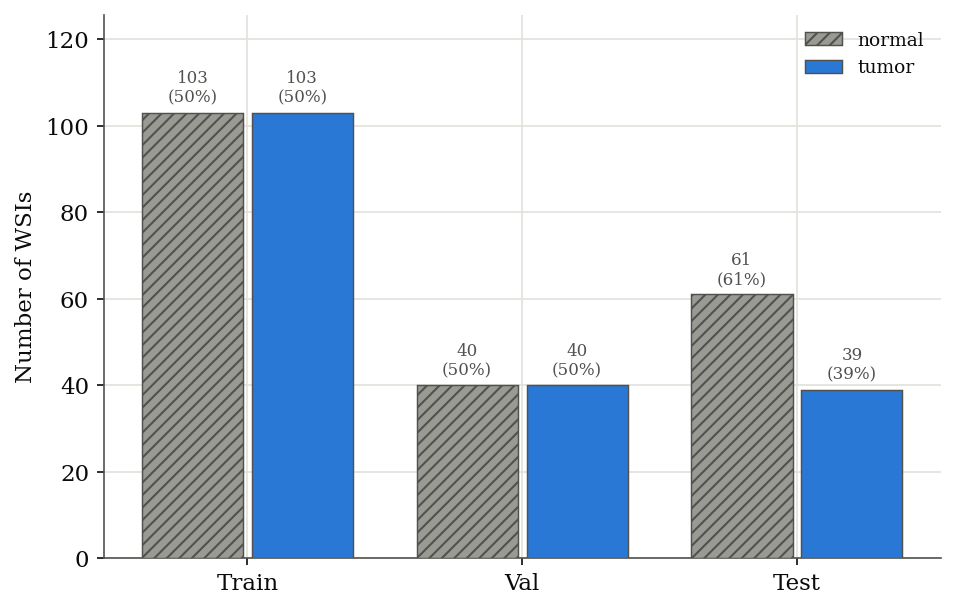

In [8]:

bar_chart(
    camelyon_wsi_tumor, "class", "n", "pct_of_split",
    "CAMELYON17 — WSI-level class distribution (tumor_status)",
    FIGURES_DIR / "camelyon_wsi_level_tumor_status.png",
    colors={"normal": NEUTRAL, "tumor": ACCENT}, class_order=["normal", "tumor"],
    ylabel="Number of WSIs",
)


In [9]:

camelyon_wsi_stage = save_table(
    wsi_level_table(camelyon_dfs, "stage", ["negative", "itc", "micro", "macro"]),
    "camelyon_wsi_level_stage",
)
camelyon_wsi_stage


,split,class,n,pct_of_split,n_total_split,majority_minority_ratio
0,train,negative,103,50.0,206,2.45:1
1,train,itc,20,9.7,206,None
2,train,micro,41,19.9,206,None
3,train,macro,42,20.4,206,None
4,val,negative,40,50.0,80,2.11:1
5,val,itc,8,10.0,80,None
6,val,micro,13,16.2,80,None
7,val,macro,19,23.8,80,None
8,test,negative,61,61.0,100,2.35:1
9,test,itc,8,8.0,100,None


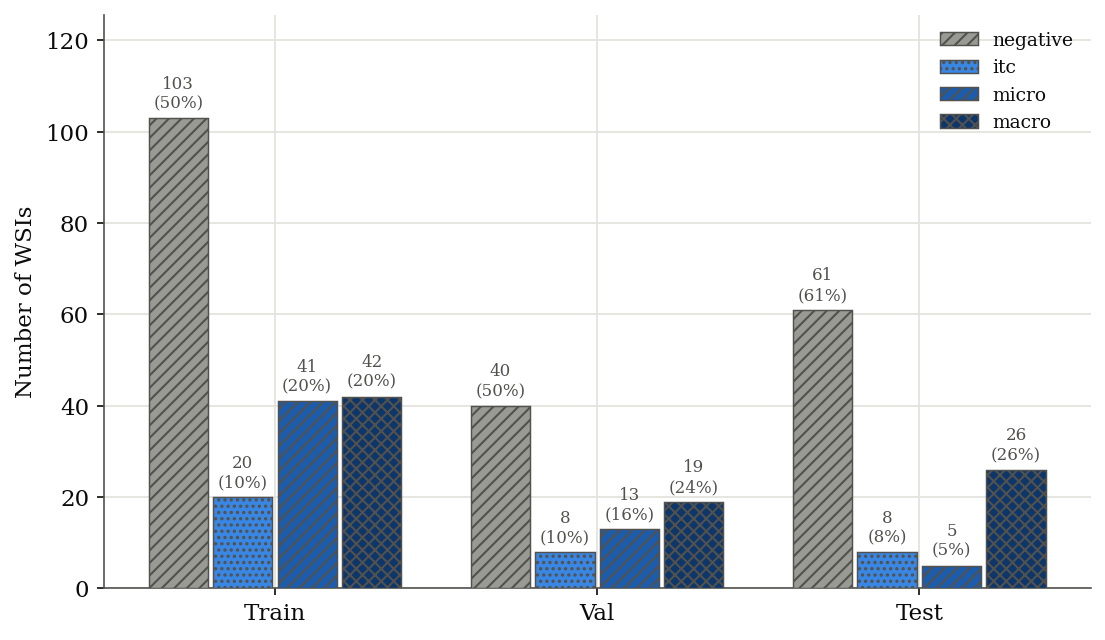

In [10]:

bar_chart(
    camelyon_wsi_stage, "class", "n", "pct_of_split",
    "CAMELYON17 — WSI-level stage breakdown",
    FIGURES_DIR / "camelyon_stage_breakdown.png",
    colors={"negative": NEUTRAL, "itc": SEQ_RAMP[1], "micro": SEQ_RAMP[2], "macro": SEQ_RAMP[3]},
    class_order=["negative", "itc", "micro", "macro"], ylabel="Number of WSIs", figsize=(7.5, 4.4),
)


In [11]:

camelyon_patient = save_table(
    patient_level_table(camelyon_dfs, "tumor_status", "patient_id", ["normal", "tumor"], positive_priority="tumor"),
    "camelyon_patient_level_tumor_status",
)
camelyon_patient


,split,class,n_patients,pct_of_split,n_total_patients,n_patients_with_disagreeing_slides,majority_minority_ratio
0,train,normal,16,26.7,60,31,2.75:1
1,train,tumor,44,73.3,60,31,None
2,val,normal,3,15.0,20,13,5.67:1
3,val,tumor,17,85.0,20,13,None
4,test,normal,5,25.0,20,14,3.00:1
5,test,tumor,15,75.0,20,14,None


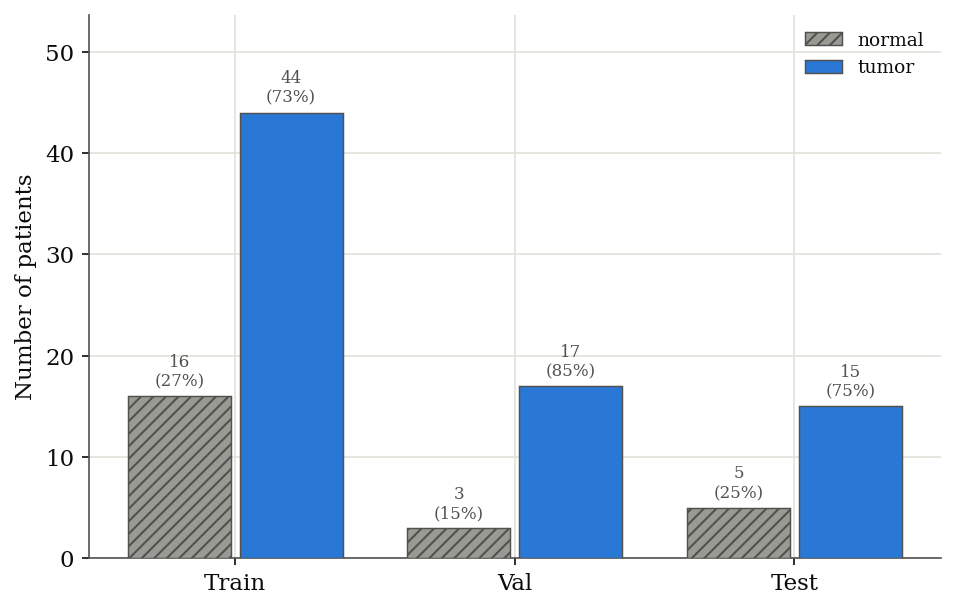

In [12]:

bar_chart(
    camelyon_patient, "class", "n_patients", "pct_of_split",
    "CAMELYON17 — patient-level class distribution (any-tumor rule)",
    FIGURES_DIR / "camelyon_patient_level_tumor_status.png",
    colors={"normal": NEUTRAL, "tumor": ACCENT}, class_order=["normal", "tumor"],
    ylabel="Number of patients",
)


In [13]:

camelyon_ds_tumor = save_table(
    dataset_level_table(camelyon_all, "tumor_status", ["normal", "tumor"]),
    "camelyon_dataset_tumor_status",
)
camelyon_ds_tumor


,class,n,pct,n_total,majority_minority_ratio
0,normal,204,52.8,386,1.12:1
1,tumor,182,47.2,386,None


In [14]:

camelyon_ds_stage = save_table(
    dataset_level_table(camelyon_all, "stage", ["negative", "itc", "micro", "macro"]),
    "camelyon_dataset_stage",
)
camelyon_ds_stage


,class,n,pct,n_total,majority_minority_ratio
0,negative,204,52.8,386,2.34:1
1,itc,36,9.3,386,None
2,micro,59,15.3,386,None
3,macro,87,22.5,386,None


In [15]:

camelyon_ds_patient = save_table(
    dataset_patient_level_table(camelyon_all, "tumor_status", "patient_id", ["normal", "tumor"], positive_priority="tumor"),
    "camelyon_dataset_patient_tumor_status",
)
camelyon_ds_patient


,class,n_patients,pct,n_total_patients,n_patients_with_disagreeing_slides,majority_minority_ratio
0,normal,24,24.0,100,58,3.17:1
1,tumor,76,76.0,100,58,None


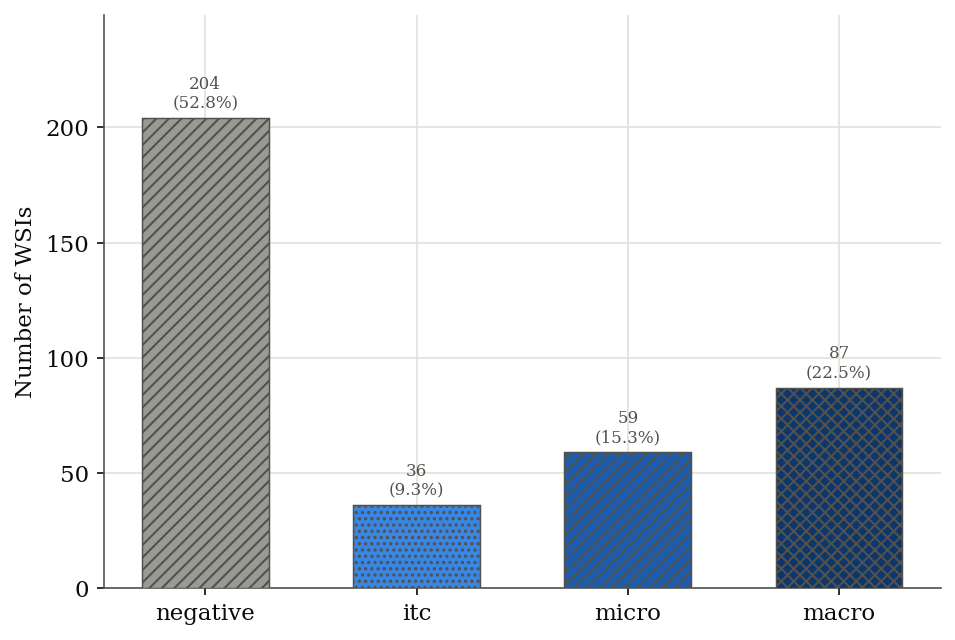

In [16]:

camelyon_stage_colors = {"negative": NEUTRAL, "itc": SEQ_RAMP[1], "micro": SEQ_RAMP[2], "macro": SEQ_RAMP[3]}
categorical_bar_chart(
    camelyon_all["stage"].value_counts().reindex(["negative", "itc", "micro", "macro"]).dropna(),
    "CAMELYON17 — stage distribution (Slide, dataset-wide)",
    FIGURES_DIR / "camelyon_stage_dataset_wide.png",
    camelyon_stage_colors, ylabel="Number of WSIs",
)


In [17]:

camelyon_center_counts = camelyon_all["center"].value_counts().sort_index()
camelyon_center_table = save_table(
    camelyon_center_counts.rename_axis("center").reset_index(name="n_slides").assign(
        pct=lambda d: (100 * d["n_slides"] / d["n_slides"].sum()).round(1),
        n_patients=lambda d: d["center"].map(camelyon_all.groupby("center")["patient_id"].nunique()),
    ),
    "camelyon_center_distribution",
)
camelyon_center_table


,center,n_slides,pct,n_patients
0,0,70,18.1,20
1,1,74,19.2,20
2,2,62,16.1,20
3,3,80,20.7,20
4,4,100,25.9,20


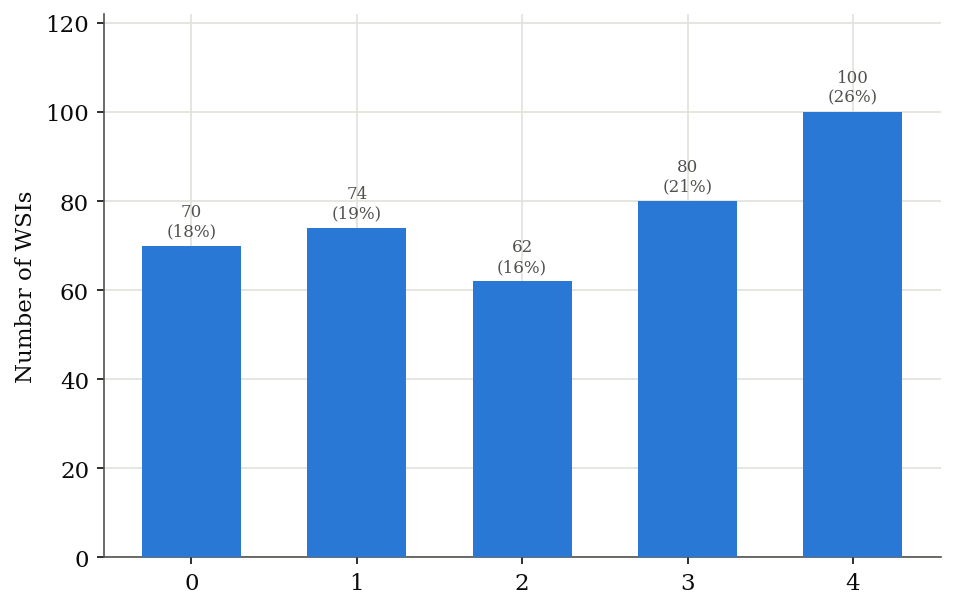

In [18]:

single_series_bar_chart(
    camelyon_center_counts, "CAMELYON17 — WSI count by center",
    FIGURES_DIR / "camelyon_center_distribution.png", ylabel="Number of WSIs", color=ACCENT,
)


In [19]:

camelyon_center_tumor_ct = pd.crosstab(camelyon_all["center"], camelyon_all["tumor_status"])
camelyon_center_tumor_table = save_table(
    camelyon_center_tumor_ct.reset_index(), "camelyon_center_x_tumor_status",
)
camelyon_center_tumor_table


tumor_status,center,normal,tumor
0,0,34,36
1,1,32,42
2,2,37,25
3,3,40,40
4,4,61,39


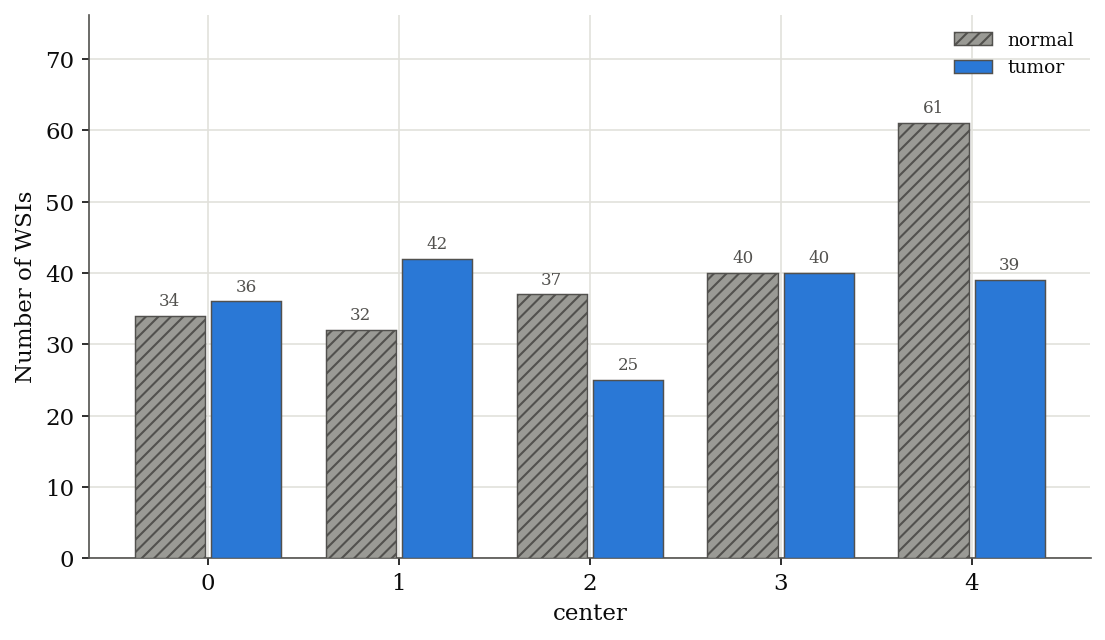

In [20]:

grouped_crosstab_chart(
    camelyon_center_tumor_ct, "CAMELYON17 — tumor_status by center",
    FIGURES_DIR / "camelyon_center_x_tumor_status.png",
    colors={"normal": NEUTRAL, "tumor": ACCENT}, class_order=["normal", "tumor"],
    ylabel="Number of WSIs", xlabel="center",
)


In [21]:

camelyon_center_stage_ct = pd.crosstab(camelyon_all["center"], camelyon_all["stage"])
camelyon_center_stage_table = save_table(
    camelyon_center_stage_ct.reset_index(), "camelyon_center_x_stage",
)
camelyon_center_stage_table


stage,center,itc,macro,micro,negative
0,0,11,15,10,34
1,1,7,12,23,32
2,2,2,15,8,37
3,3,8,19,13,40
4,4,8,26,5,61


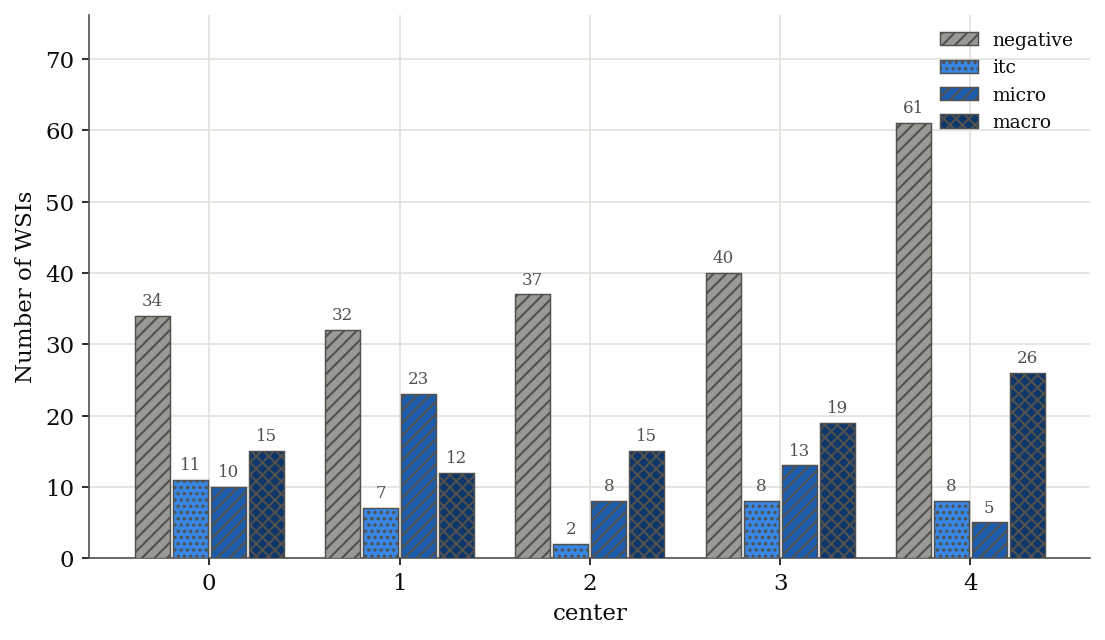

In [22]:

grouped_crosstab_chart(
    camelyon_center_stage_ct, "CAMELYON17 — stage by center",
    FIGURES_DIR / "camelyon_center_x_stage.png",
    colors={"negative": NEUTRAL, "itc": SEQ_RAMP[1], "micro": SEQ_RAMP[2], "macro": SEQ_RAMP[3]},
    class_order=["negative", "itc", "micro", "macro"], ylabel="Number of WSIs", xlabel="center",
)


In [23]:

camelyon_center_annot_ct = pd.crosstab(camelyon_all["center"], camelyon_all["annotation_used"])
camelyon_center_annot_table = save_table(camelyon_center_annot_ct.reset_index(), "camelyon_center_x_annotation_used")
camelyon_center_annot_table


annotation_used,center,no,yes
0,0,60,10
1,1,64,10
2,2,52,10
3,3,70,10
4,4,90,10


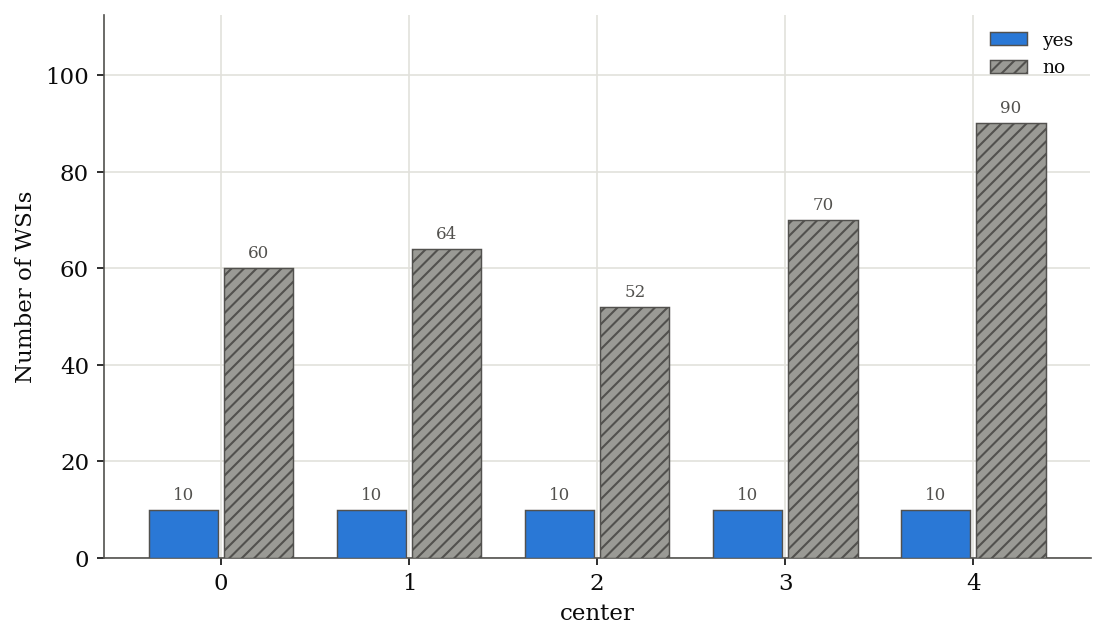

In [24]:

grouped_crosstab_chart(
    camelyon_center_annot_ct, "CAMELYON17 — annotation_used by center",
    OVERVIEW_FIGURES_DIR / "camelyon_center_x_annotation_used.png",
    colors={"yes": ACCENT, "no": NEUTRAL}, class_order=["yes", "no"],
    ylabel="Number of WSIs", xlabel="center",
)


In [25]:

gsdb_wsi = save_table(
    wsi_level_table(gsdb_dfs, "inflammation_status", ["inflamed", "noninflamed", "other"]),
    "gsdb_wsi_level_inflammation_status",
)
gsdb_wsi


,split,class,n,pct_of_split,n_total_split,majority_minority_ratio
0,train,inflamed,82,55.0,149,1.37:1
1,train,noninflamed,60,40.3,149,None
2,train,other,7,4.7,149,None
3,val,inflamed,22,47.8,46,1.05:1
4,val,noninflamed,21,45.7,46,None
5,val,other,3,6.5,46,None
6,test,inflamed,34,64.2,53,1.79:1
7,test,noninflamed,19,35.8,53,None


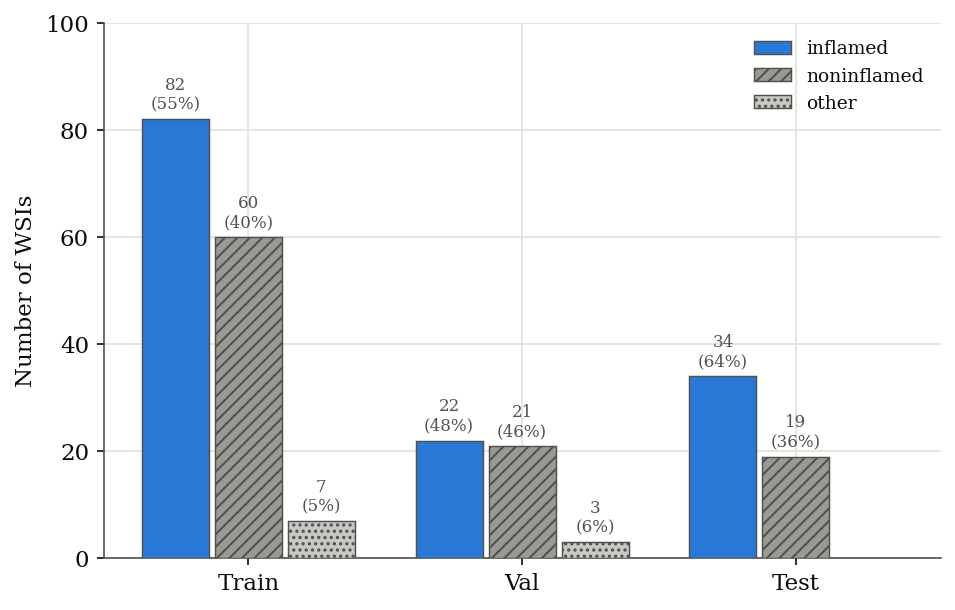

In [26]:

bar_chart(
    gsdb_wsi, "class", "n", "pct_of_split",
    "GSDB — WSI-level class distribution (inflammation_status)",
    FIGURES_DIR / "gsdb_wsi_level_inflammation_status.png",
    colors={"inflamed": ACCENT, "noninflamed": NEUTRAL, "other": LIGHT_GRAY},
    class_order=["inflamed", "noninflamed", "other"], ylabel="Number of WSIs",
)


In [27]:

gsdb_patient = save_table(
    patient_level_table(gsdb_dfs, "inflammation_status", "patient_id", ["inflamed", "noninflamed", "other"], positive_priority="inflamed"),
    "gsdb_patient_level_inflammation_status",
)
gsdb_patient


,split,class,n_patients,pct_of_split,n_total_patients,n_patients_with_disagreeing_slides,majority_minority_ratio
0,train,inflamed,68,51.1,133,0,1.13:1
1,train,noninflamed,60,45.1,133,0,None
2,train,other,5,3.8,133,0,None
3,val,inflamed,20,45.5,44,0,1.05:1
4,val,noninflamed,21,47.7,44,0,None
5,val,other,3,6.8,44,0,None
6,test,inflamed,26,57.8,45,0,1.37:1
7,test,noninflamed,19,42.2,45,0,None


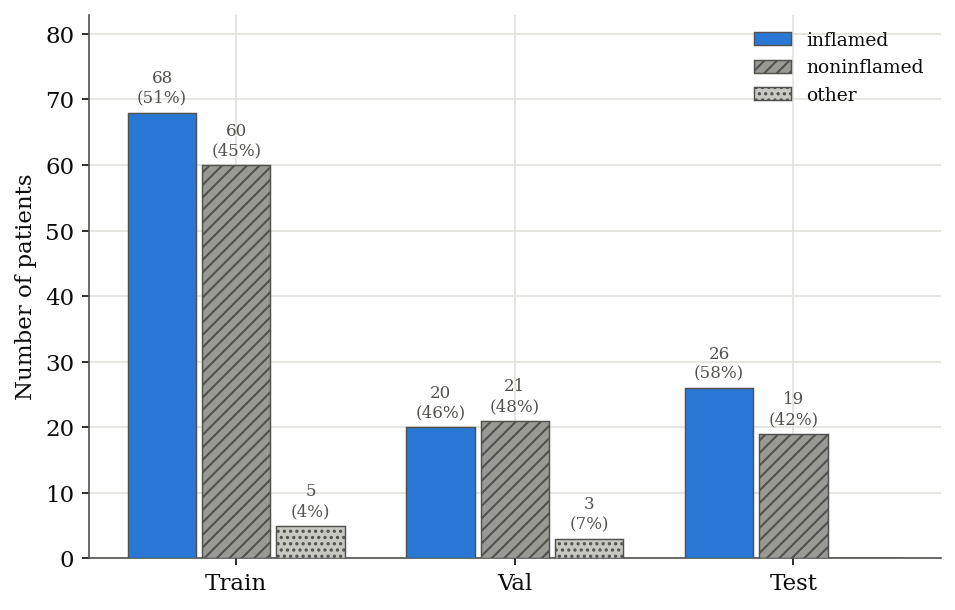

In [28]:

bar_chart(
    gsdb_patient, "class", "n_patients", "pct_of_split",
    "GSDB — patient-level class distribution (inflammation_status)",
    FIGURES_DIR / "gsdb_patient_level_inflammation_status.png",
    colors={"inflamed": ACCENT, "noninflamed": NEUTRAL, "other": LIGHT_GRAY},
    class_order=["inflamed", "noninflamed", "other"], ylabel="Number of patients",
)


In [29]:

gsdb_ds_infl = save_table(
    dataset_level_table(gsdb_all, "inflammation_status", ["inflamed", "noninflamed", "other"]),
    "gsdb_dataset_inflammation_status",
)
gsdb_ds_infl


,class,n,pct,n_total,majority_minority_ratio
0,inflamed,138,55.6,248,1.38:1
1,noninflamed,100,40.3,248,None
2,other,10,4.0,248,None


In [30]:

gsdb_ds_patient = save_table(
    dataset_patient_level_table(gsdb_all, "inflammation_status", "patient_id", ["inflamed", "noninflamed", "other"], positive_priority="inflamed"),
    "gsdb_dataset_patient_inflammation_status",
)
gsdb_ds_patient


,class,n_patients,pct,n_total_patients,n_patients_with_disagreeing_slides,majority_minority_ratio
0,inflamed,114,51.4,222,0,1.14:1
1,noninflamed,100,45.0,222,0,None
2,other,8,3.6,222,0,None


In [31]:

gsdb_scanner_counts = gsdb_all["scanner_id"].value_counts().sort_index()
gsdb_scanner_table = save_table(
    gsdb_scanner_counts.rename_axis("scanner_id").reset_index(name="n_slides").assign(
        pct=lambda d: (100 * d["n_slides"] / d["n_slides"].sum()).round(1),
        n_patients=lambda d: d["scanner_id"].map(gsdb_all.groupby("scanner_id")["patient_id"].nunique()),
    ),
    "gsdb_scanner_distribution",
)
gsdb_scanner_table


,scanner_id,n_slides,pct,n_patients
0,1,248,100.0,222


In [32]:

gsdb_full_scanner_counts = gsdb_full["scanner_id"].value_counts().sort_index()
gsdb_full_scanner_table = save_table(
    gsdb_full_scanner_counts.rename_axis("scanner_id").reset_index(name="n_slides").assign(
        pct=lambda d: (100 * d["n_slides"] / d["n_slides"].sum()).round(1),
        n_patients=lambda d: d["scanner_id"].map(gsdb_full.groupby("scanner_id")["patient_id"].nunique()),
    ),
    "gsdb_full_scanner_distribution",
)
gsdb_full_scanner_table


,scanner_id,n_slides,pct,n_patients
0,1,248,73.4,222
1,2,90,26.6,30


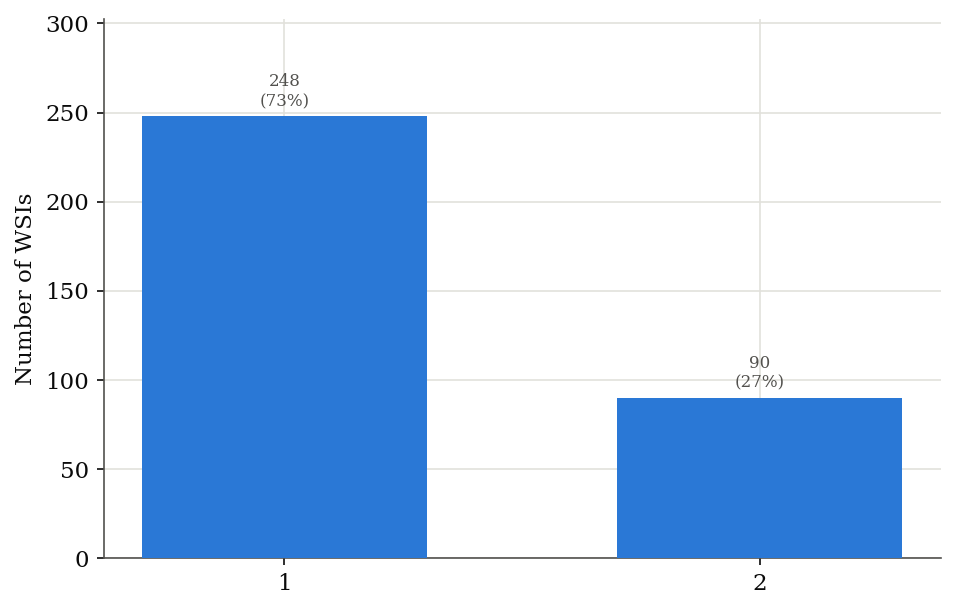

In [33]:

single_series_bar_chart(
    gsdb_full_scanner_counts, "GSDB — WSI count by scanner (full corpus incl. scanner2)",
    OVERVIEW_FIGURES_DIR / "gsdb_full_scanner_distribution.png", ylabel="Number of WSIs", color=ACCENT,
)


In [34]:

gsdb_scanner_infl_ct = pd.crosstab(gsdb_full["scanner_id"], gsdb_full["inflammation_status"])
gsdb_scanner_infl_table = save_table(gsdb_scanner_infl_ct.reset_index(), "gsdb_scanner_x_inflammation_status")
gsdb_scanner_infl_table


inflammation_status,scanner_id,inflamed,noninflamed,other
0,1,138,100,10
1,2,60,30,0


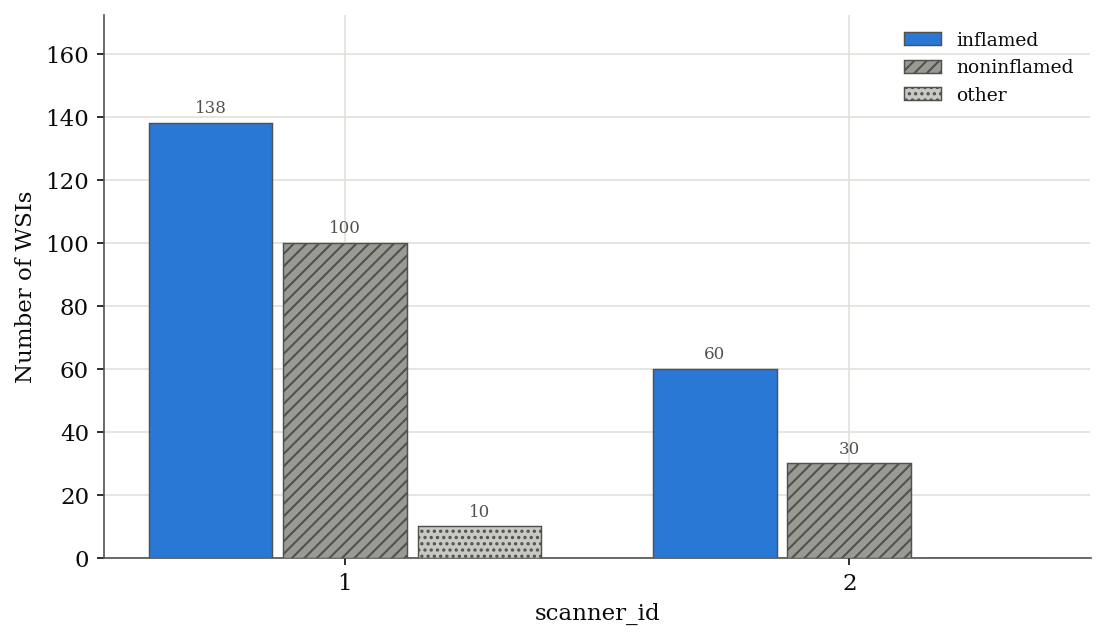

In [35]:

grouped_crosstab_chart(
    gsdb_scanner_infl_ct, "GSDB — inflammation_status by scanner (full corpus)",
    OVERVIEW_FIGURES_DIR / "gsdb_scanner_x_inflammation_status.png",
    colors={"inflamed": ACCENT, "noninflamed": NEUTRAL, "other": LIGHT_GRAY},
    class_order=["inflamed", "noninflamed", "other"], ylabel="Number of WSIs", xlabel="scanner_id",
)


In [36]:

gsdb_scanner_stain_ct = pd.crosstab(gsdb_full["scanner_id"], gsdb_full["stain"])
gsdb_scanner_stain_table = save_table(gsdb_scanner_stain_ct.reset_index(), "gsdb_scanner_x_stain")
gsdb_scanner_stain_table


stain,scanner_id,HE,MG,PAS
0,1,210,14,24
1,2,30,30,30


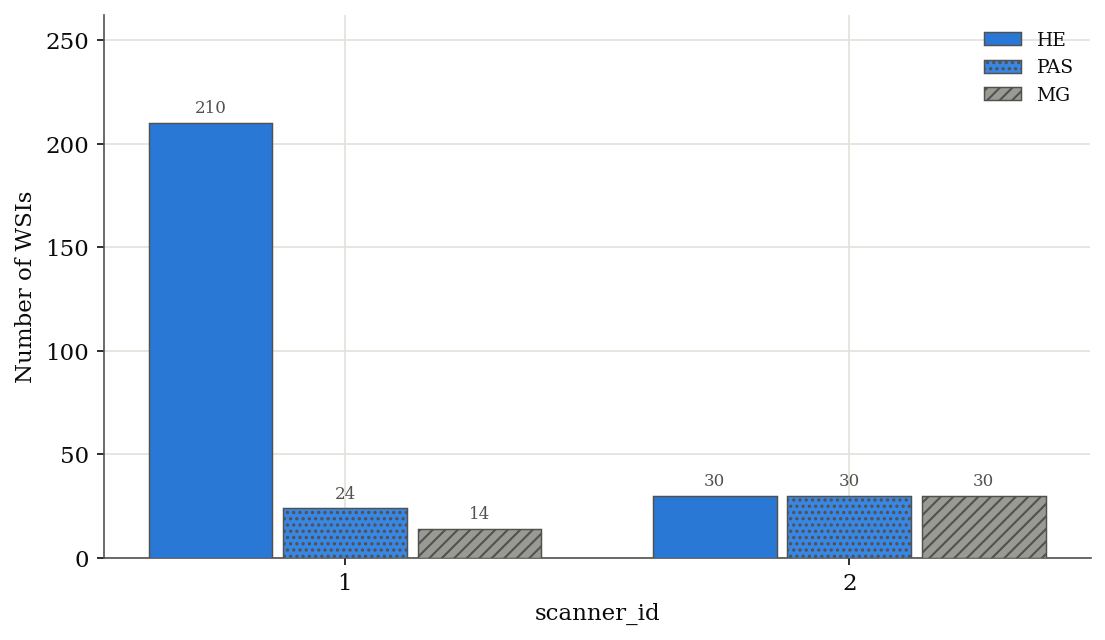

In [37]:

grouped_crosstab_chart(
    gsdb_scanner_stain_ct, "GSDB — stain by scanner (full corpus)",
    OVERVIEW_FIGURES_DIR / "gsdb_scanner_x_stain.png",
    colors={"HE": ACCENT, "PAS": SEQ_RAMP[1], "MG": NEUTRAL},
    class_order=["HE", "PAS", "MG"], ylabel="Number of WSIs", xlabel="scanner_id",
)


In [38]:

gsdb_stain_counts = gsdb_all["stain"].value_counts()
gsdb_stain_table = save_table(
    gsdb_stain_counts.rename_axis("stain").reset_index(name="n_slides").assign(
        pct=lambda d: (100 * d["n_slides"] / d["n_slides"].sum()).round(1),
        n_patients=lambda d: d["stain"].map(gsdb_all.groupby("stain")["patient_id"].nunique()),
    ),
    "gsdb_stain_distribution",
)
gsdb_stain_table


,stain,n_slides,pct,n_patients
0,HE,210,84.7,210
1,PAS,24,9.7,24
2,MG,14,5.6,14


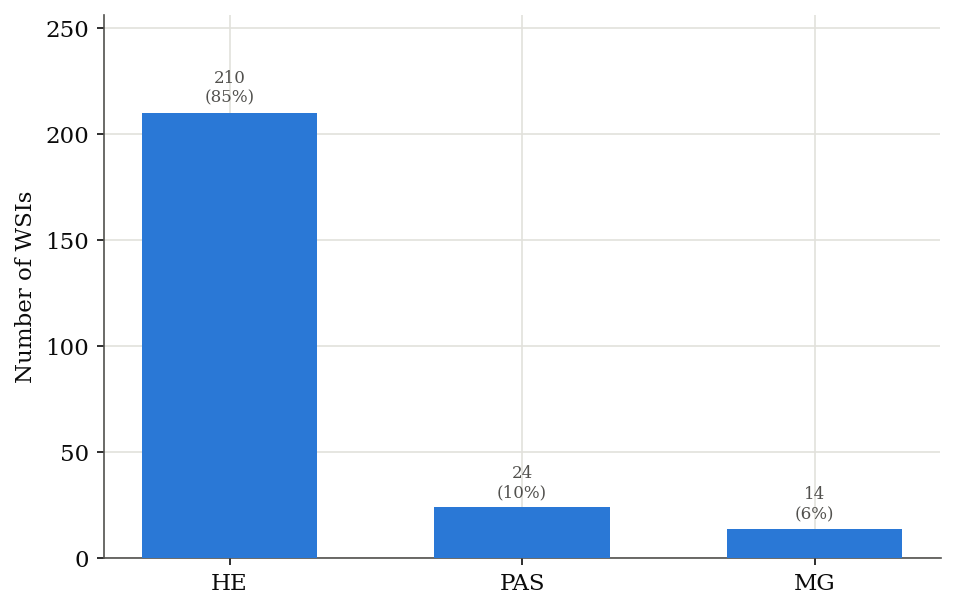

In [39]:

single_series_bar_chart(
    gsdb_stain_counts, "GSDB — WSI count by stain",
    FIGURES_DIR / "gsdb_stain_distribution.png", ylabel="Number of WSIs", color=ACCENT,
)


In [40]:

gsdb_stain_infl_ct = pd.crosstab(gsdb_all["stain"], gsdb_all["inflammation_status"])
gsdb_stain_infl_table = save_table(gsdb_stain_infl_ct.reset_index(), "gsdb_stain_x_inflammation_status")
gsdb_stain_infl_table


inflammation_status,stain,inflamed,noninflamed,other
0,HE,108,96,6
1,MG,12,1,1
2,PAS,18,3,3


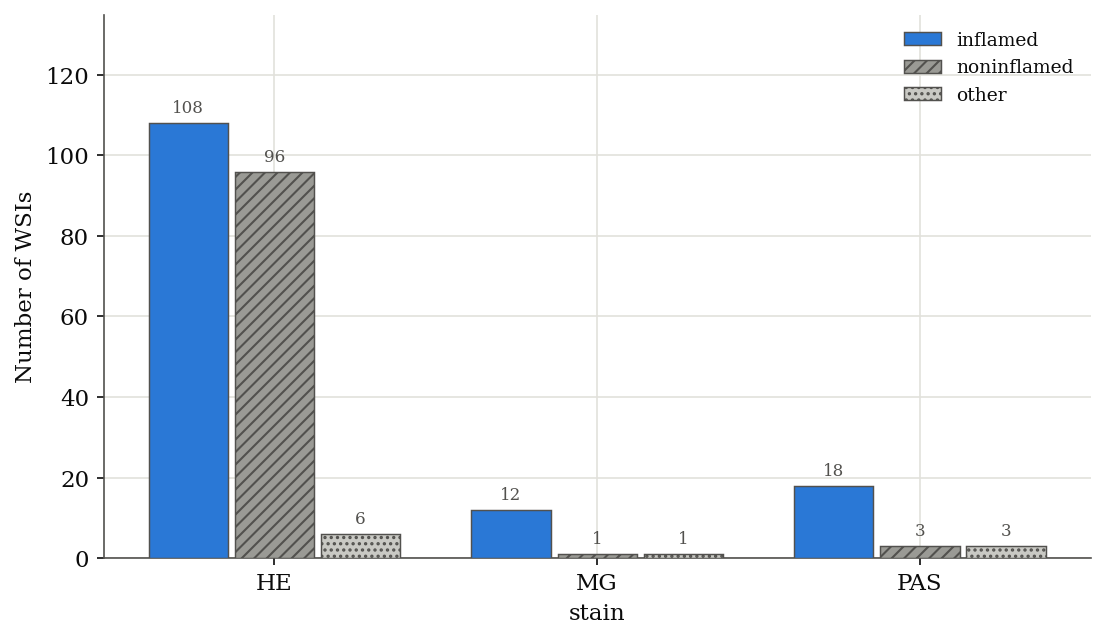

In [41]:

grouped_crosstab_chart(
    gsdb_stain_infl_ct, "GSDB — inflammation_status by stain",
    FIGURES_DIR / "gsdb_stain_x_inflammation_status.png",
    colors={"inflamed": ACCENT, "noninflamed": NEUTRAL, "other": LIGHT_GRAY},
    class_order=["inflamed", "noninflamed", "other"], ylabel="Number of WSIs", xlabel="stain",
)


In [42]:

camelyon_region_level = save_table(
    patch_region_level_table(camelyon_dfs, camelyon_hier, "region", ["negative", "positive", "unknown", "mixed"]),
    "camelyon_region_level_status",
)
camelyon_region_level


,split,class,n,pct_of_split,n_regions_total_split,n_slides_matched,n_slides_in_split
0,train,positive,240,3.47,6923,203,206
1,train,unknown,6683,96.53,6923,203,206
2,val,positive,47,4.42,1064,79,80
3,val,unknown,1017,95.58,1064,79,80
4,test,positive,25,0.13,18711,98,100
5,test,unknown,18686,99.87,18711,98,100


In [43]:

camelyon_patch_level = save_table(
    patch_region_level_table(camelyon_dfs, camelyon_hier, "patch", ["negative", "positive", "unknown", "mixed"]),
    "camelyon_patch_level_status",
)
camelyon_patch_level


,split,class,n,pct_of_split,n_patches_total_split,n_slides_matched,n_slides_in_split
0,train,positive,20225,0.32,6327500,203,206
1,train,unknown,6307275,99.68,6327500,203,206
2,val,positive,15388,0.69,2231700,79,80
3,val,unknown,2216312,99.31,2231700,79,80
4,test,positive,33889,0.91,3714850,98,100
5,test,unknown,3680961,99.09,3714850,98,100


In [44]:

camelyon_ds_region = save_table(
    dataset_patch_region_level_table(camelyon_all, camelyon_hier, "region", ["negative", "positive", "unknown", "mixed"]),
    "camelyon_dataset_region_status",
)
camelyon_ds_region


,class,n,pct,n_regions_total,n_slides_matched,n_slides_total
0,positive,312,1.17,26698,380,386
1,unknown,26386,98.83,26698,380,386


In [45]:

camelyon_ds_patch = save_table(
    dataset_patch_region_level_table(camelyon_all, camelyon_hier, "patch", ["negative", "positive", "unknown", "mixed"]),
    "camelyon_dataset_patch_status",
)
camelyon_ds_patch


,class,n,pct,n_patches_total,n_slides_matched,n_slides_total
0,positive,69502,0.57,12274050,380,386
1,unknown,12204548,99.43,12274050,380,386


In [46]:

camelyon_graph_overview, camelyon_missing = graph_corpus_overview(
    camelyon_all, camelyon_hier, CAMELYON_GRAPH_DIR, "tumor_status", ["normal", "tumor"],
)
save_table(camelyon_graph_overview, "camelyon_graph_corpus_overview")
camelyon_graph_overview


,graph_dir,n_pt_files_on_disk,n_split_slides,n_matched,n_missing,n_normal,pct_normal,n_tumor,pct_tumor
0,context_aware_camelyon_domain_robust_labels,494,386,380,6,204,53.7,176,46.3


In [47]:

camelyon_records = load_hier_records(CAMELYON_HIER_JSON)
camelyon_slide_status_dist = save_table(
    slide_field_distribution(camelyon_records, "slide_status").rename_axis("slide_status").reset_index(name="n_graphs"),
    "camelyon_graph_slide_status_distribution",
)
camelyon_slide_status_dist


,slide_status,n_graphs
0,unknown,450
1,positive,44


In [48]:

camelyon_slide_stage_dist = save_table(
    slide_field_distribution(camelyon_records, "slide_stage").rename_axis("slide_stage").reset_index(name="n_graphs"),
    "camelyon_graph_slide_stage_distribution",
)
camelyon_slide_stage_dist


,slide_stage,n_graphs
0,pN1,148
1,pN0,120
2,pN1mi,105
3,pN2,70
4,pN0(i+),51


In [49]:

camelyon_struct_stats = save_table(
    graph_structural_stats(camelyon_records).reset_index().rename(columns={"index": "metric"}),
    "camelyon_graph_structural_stats",
)
camelyon_struct_stats


,metric,sum,count,mean,std,min,median,max
0,num_patches,1.491841e+07,494.0,3.019921e+04,2.381479e+04,1081.0,22997.5,1.343160e+05
1,num_regions,3.014000e+04,494.0,6.101000e+01,3.645400e+02,1.0,16.0,7.321000e+03
2,annotated_patches,6.950200e+04,494.0,1.406900e+02,1.499200e+03,0.0,0.0,3.000800e+04
3,total_patches,1.491841e+07,494.0,3.019921e+04,2.381479e+04,1081.0,22997.5,1.343160e+05
4,annotated_regions,3.120000e+02,494.0,6.300000e-01,3.500000e+00,0.0,0.0,4.300000e+01
5,total_regions,3.014000e+04,494.0,6.101000e+01,3.645400e+02,1.0,16.0,7.321000e+03
6,file_size_bytes,1.950160e+11,494.0,3.947691e+08,3.112993e+08,14145251.0,300562051.0,1.753151e+09
7,patch_annotation_coverage_frac,1.130000e+00,494.0,0.000000e+00,2.000000e-02,0.0,0.0,4.700000e-01


In [50]:

camelyon_overview_facts = pd.DataFrame([{
    "n_slides_total": len(camelyon_all),
    "n_patients_total": camelyon_all["patient_id"].nunique(),
    "n_centers": camelyon_all["center"].nunique(),
    "n_graphs_on_disk": len(list(CAMELYON_GRAPH_DIR.glob("*.pt"))),
    "total_corpus_size_gb": round(sum(r.get("file_size_bytes") or 0 for r in camelyon_records) / 1e9, 1),
}])
save_table(camelyon_overview_facts, "camelyon_overview_facts")
camelyon_overview_facts


,n_slides_total,n_patients_total,n_centers,n_graphs_on_disk,total_corpus_size_gb
0,386,100,5,494,195.0


In [51]:

camelyon_slide_counts = camelyon_all["tumor_status"].value_counts().to_dict()
camelyon_region_counts = counts_dict(dataset_patch_region_level_table(camelyon_all, camelyon_hier, "region", ["negative", "positive", "unknown", "mixed"]))
camelyon_patch_counts = counts_dict(dataset_patch_region_level_table(camelyon_all, camelyon_hier, "patch", ["negative", "positive", "unknown", "mixed"]))


In [52]:

camelyon_status_colors = {"positive": ACCENT, "tumor": ACCENT, "negative": NEUTRAL, "normal": NEUTRAL,
                           "unknown": UNKNOWN_GRAY, "mixed": MIXED_GRAY}
camelyon_status_class_order = ["positive", "negative", "unknown", "mixed"]

camelyon_slide_counts_aliased = {"positive": camelyon_slide_counts.get("tumor", 0),
                                  "negative": camelyon_slide_counts.get("normal", 0)}
camelyon_status_by_granularity = {
    "Slide": camelyon_slide_counts_aliased,
    "Region": camelyon_region_counts,
    "Patch": camelyon_patch_counts,
}
camelyon_status_detail = save_table(
    detailed_table(camelyon_status_by_granularity, camelyon_status_class_order),
    "camelyon_tumor_status_detailed_by_granularity",
)
camelyon_status_detail


,granularity,class,n,pct_of_granularity,n_total_at_granularity
0,Slide,positive,182,47.15,386
1,Slide,negative,204,52.85,386
2,Region,positive,312,1.17,26698
3,Region,unknown,26386,98.83,26698
4,Patch,positive,69502,0.57,12274050
5,Patch,unknown,12204548,99.43,12274050


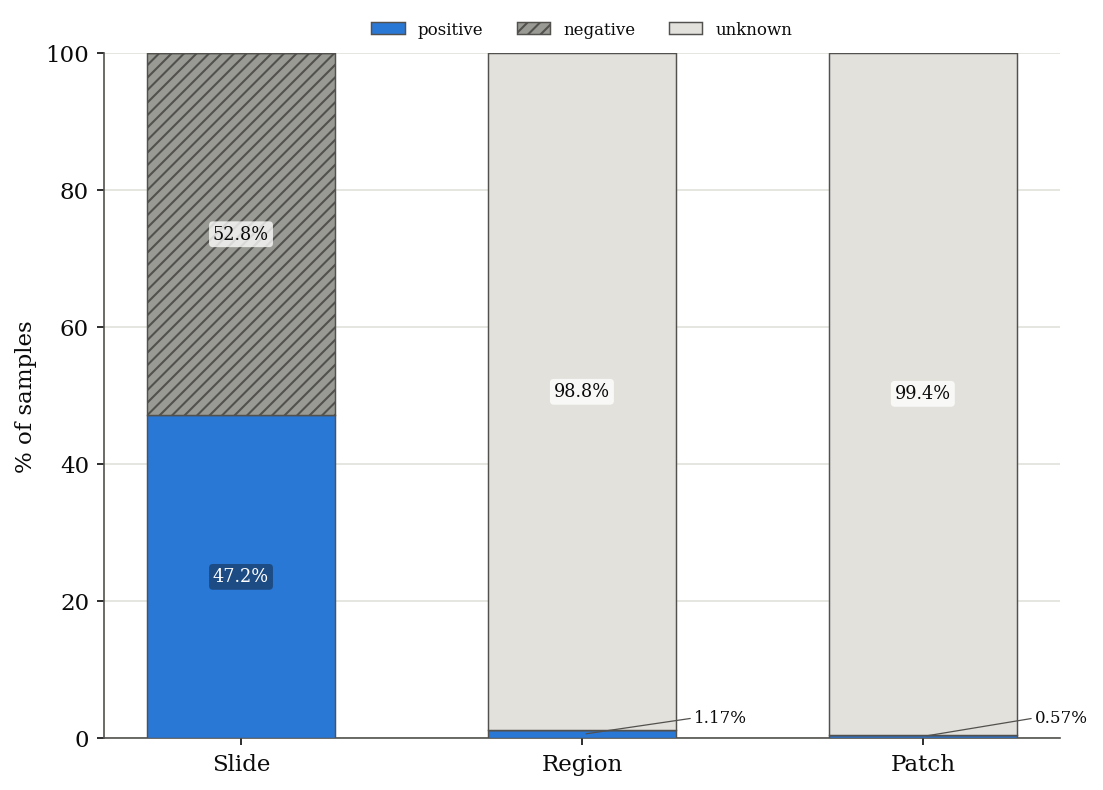

In [53]:

detailed_stacked_chart(
    camelyon_status_by_granularity, "CAMELYON17 — tumor_status breakdown by granularity",
    IMBALANCE_FIGURES_DIR / "camelyon_tumor_status_detailed_by_granularity.png",
    camelyon_status_class_order, camelyon_status_colors,
)


In [54]:

gsdb_region_level = save_table(
    patch_region_level_table(gsdb_dfs, gsdb_infl_hier, "region", ["inflamed", "noninflamed", "other", "unknown", "mixed"]),
    "gsdb_region_level_inflammation_status",
)
gsdb_region_level


,split,class,n,pct_of_split,n_regions_total_split,n_slides_matched,n_slides_in_split
0,train,inflamed,6948,34.50,20137,145,149
1,train,noninflamed,2880,14.30,20137,145,149
2,train,other,668,3.32,20137,145,149
3,train,unknown,4158,20.65,20137,145,149
4,train,mixed,5483,27.23,20137,145,149
5,val,inflamed,2194,37.80,5805,46,46
6,val,noninflamed,1191,20.52,5805,46,46
7,val,other,211,3.63,5805,46,46
8,val,unknown,34,0.59,5805,46,46
9,val,mixed,2175,37.47,5805,46,46


In [55]:

gsdb_patch_level = save_table(
    patch_region_level_table(gsdb_dfs, gsdb_infl_hier, "patch", ["inflamed", "noninflamed", "other", "unknown", "mixed"]),
    "gsdb_patch_level_inflammation_status",
)
gsdb_patch_level


,split,class,n,pct_of_split,n_patches_total_split,n_slides_matched,n_slides_in_split
0,train,inflamed,654374,47.15,1387854,145,149
1,train,noninflamed,343502,24.75,1387854,145,149
2,train,other,55507,4.00,1387854,145,149
3,train,unknown,334471,24.10,1387854,145,149
4,val,inflamed,225507,56.38,399984,46,46
5,val,noninflamed,140137,35.04,399984,46,46
6,val,other,21328,5.33,399984,46,46
7,val,unknown,13012,3.25,399984,46,46
8,test,inflamed,253801,70.18,361652,53,53
9,test,noninflamed,97221,26.88,361652,53,53


In [56]:

def tissue_type_level_table(dfs, hier, node_type):
    key = f"{node_type}_tissue_type_counts"
    rows = []
    for sp in SPLITS:
        df = dfs[sp]
        totals = Counter()
        for slide_name in df["slide_name"]:
            rec = hier.get(slide_name)
            if rec is None:
                continue
            for cls, n in rec.get(key, {}).items():
                totals[cls] += n
        grand_total = sum(totals.values())
        class_order = ["antrum", "corpus", "other", "unknown", "mixed", "intermediate"]
        ordered = [c for c in class_order if c in totals] + [c for c in totals if c not in class_order]
        node_label = "patches" if node_type == "patch" else "regions"
        for cls in ordered:
            n = totals[cls]
            rows.append({
                "split": sp, "class": cls, "n": n,
                "pct_of_split": round(100 * n / grand_total, 2) if grand_total else 0.0,
                f"n_{node_label}_total_split": grand_total,
            })
    return pd.DataFrame(rows)


gsdb_region_tissue_type = save_table(
    tissue_type_level_table(gsdb_dfs, gsdb_tissue_hier, "region"), "gsdb_region_level_tissue_type",
)
gsdb_region_tissue_type


,split,class,n,pct_of_split,n_regions_total_split
0,train,antrum,4350,21.60,20137
1,train,corpus,5748,28.54,20137
2,train,other,84,0.42,20137
3,train,unknown,4158,20.65,20137
4,train,mixed,5483,27.23,20137
5,train,intermediate,314,1.56,20137
6,val,antrum,1284,22.12,5805
7,val,corpus,2021,34.81,5805
8,val,other,22,0.38,5805
9,val,unknown,34,0.59,5805


In [57]:

gsdb_patch_tissue_type = save_table(
    tissue_type_level_table(gsdb_dfs, gsdb_tissue_hier, "patch"), "gsdb_patch_level_tissue_type",
)
gsdb_patch_tissue_type


,split,class,n,pct_of_split,n_patches_total_split
0,train,antrum,425040,30.63,1387854
1,train,corpus,579901,41.78,1387854
2,train,other,13029,0.94,1387854
3,train,unknown,334471,24.10,1387854
4,train,intermediate,35413,2.55,1387854
5,val,antrum,138218,34.56,399984
6,val,corpus,208896,52.23,399984
7,val,other,3413,0.85,399984
8,val,unknown,13012,3.25,399984
9,val,intermediate,36445,9.11,399984


In [58]:

def dataset_tissue_type_level_table(df_all, hier, node_type):
    key = f"{node_type}_tissue_type_counts"
    totals = Counter()
    for slide_name in df_all["slide_name"]:
        rec = hier.get(slide_name)
        if rec is None:
            continue
        for cls, n in rec.get(key, {}).items():
            totals[cls] += n
    grand_total = sum(totals.values())
    class_order = ["antrum", "corpus", "other", "unknown", "mixed", "intermediate"]
    ordered = [c for c in class_order if c in totals] + [c for c in totals if c not in class_order]
    node_label = "patches" if node_type == "patch" else "regions"
    rows = []
    for cls in ordered:
        n = totals[cls]
        rows.append({
            "class": cls, "n": n,
            "pct": round(100 * n / grand_total, 2) if grand_total else 0.0,
            f"n_{node_label}_total": grand_total,
        })
    return pd.DataFrame(rows)


gsdb_ds_region = save_table(
    dataset_patch_region_level_table(gsdb_all, gsdb_infl_hier, "region", ["inflamed", "noninflamed", "other", "unknown", "mixed"]),
    "gsdb_dataset_region_inflammation_status",
)
gsdb_ds_region


,class,n,pct,n_regions_total,n_slides_matched,n_slides_total
0,inflamed,11755,37.69,31187,244,248
1,noninflamed,4971,15.94,31187,244,248
2,other,879,2.82,31187,244,248
3,unknown,4216,13.52,31187,244,248
4,mixed,9366,30.03,31187,244,248


In [59]:

gsdb_ds_patch = save_table(
    dataset_patch_region_level_table(gsdb_all, gsdb_infl_hier, "patch", ["inflamed", "noninflamed", "other", "unknown", "mixed"]),
    "gsdb_dataset_patch_inflammation_status",
)
gsdb_ds_patch


,class,n,pct,n_patches_total,n_slides_matched,n_slides_total
0,inflamed,1133682,52.74,2149490,244,248
1,noninflamed,580860,27.02,2149490,244,248
2,other,76835,3.57,2149490,244,248
3,unknown,358113,16.66,2149490,244,248


In [60]:

gsdb_ds_region_tissue = save_table(
    dataset_tissue_type_level_table(gsdb_all, gsdb_tissue_hier, "region"), "gsdb_dataset_region_tissue_type",
)
gsdb_ds_region_tissue


,class,n,pct,n_regions_total
0,antrum,7327,23.49,31187
1,corpus,9403,30.15,31187
2,other,106,0.34,31187
3,unknown,4216,13.52,31187
4,mixed,9366,30.03,31187
5,intermediate,769,2.47,31187


In [61]:

gsdb_ds_patch_tissue = save_table(
    dataset_tissue_type_level_table(gsdb_all, gsdb_tissue_hier, "patch"), "gsdb_dataset_patch_tissue_type",
)
gsdb_ds_patch_tissue


,class,n,pct,n_patches_total
0,antrum,734495,34.17,2149490
1,corpus,947539,44.08,2149490
2,other,16442,0.76,2149490
3,unknown,358113,16.66,2149490
4,intermediate,92901,4.32,2149490


In [62]:

gsdb_infl_graph_overview, gsdb_infl_missing = graph_corpus_overview(
    gsdb_all, gsdb_infl_hier, GSDB_INFLAMMATION_GRAPH_DIR, "inflammation_status", ["inflamed", "noninflamed", "other"],
)
save_table(gsdb_infl_graph_overview, "gsdb_inflammation_graph_corpus_overview")
gsdb_infl_graph_overview


,graph_dir,n_pt_files_on_disk,n_split_slides,n_matched,n_missing,n_inflamed,pct_inflamed,n_noninflamed,pct_noninflamed,n_other,pct_other
0,context_aware_gsdb_inflammation,333,248,244,4,136,55.7,99,40.6,9,3.7


In [63]:

gsdb_tissue_graph_overview, gsdb_tissue_missing = graph_corpus_overview(
    gsdb_all, gsdb_tissue_hier, GSDB_TISSUE_GRAPH_DIR, "inflammation_status", ["inflamed", "noninflamed", "other"],
)
save_table(gsdb_tissue_graph_overview, "gsdb_tissue_graph_corpus_overview")
gsdb_tissue_graph_overview


,graph_dir,n_pt_files_on_disk,n_split_slides,n_matched,n_missing,n_inflamed,pct_inflamed,n_noninflamed,pct_noninflamed,n_other,pct_other
0,context_aware_gsdb_inflammation,333,248,244,4,136,55.7,99,40.6,9,3.7


In [64]:

gsdb_infl_records = load_hier_records(GSDB_INFLAMMATION_HIER_JSON)
gsdb_slide_status_dist = save_table(
    slide_field_distribution(gsdb_infl_records, "slide_status").rename_axis("slide_status").reset_index(name="n_graphs"),
    "gsdb_graph_slide_status_distribution",
)
gsdb_slide_status_dist


,slide_status,n_graphs
0,mixed,294
1,inflamed,27
2,noninflamed,12


In [65]:

gsdb_tissue_records = load_hier_records(GSDB_TISSUE_HIER_JSON)
gsdb_slide_tissue_type_dist = save_table(
    slide_field_distribution(gsdb_tissue_records, "slide_tissue_type").rename_axis("slide_tissue_type").reset_index(name="n_graphs"),
    "gsdb_graph_slide_tissue_type_distribution",
)
gsdb_slide_tissue_type_dist


,slide_tissue_type,n_graphs
0,mixed,309
1,antrum,13
2,corpus,10
3,intermediate,1


In [66]:

gsdb_infl_struct_stats = save_table(
    graph_structural_stats(gsdb_infl_records).reset_index().rename(columns={"index": "metric"}),
    "gsdb_inflammation_graph_structural_stats",
)
gsdb_infl_struct_stats


,metric,sum,count,mean,std,min,median,max
0,num_patches,2.766487e+06,333.0,8.307770e+03,1.668155e+04,294.0,5974.00,2.989780e+05
1,num_regions,4.020400e+04,333.0,1.207300e+02,2.297800e+02,4.0,88.00,4.096000e+03
2,annotated_patches,2.395806e+06,333.0,7.194610e+03,4.710490e+03,2.0,5712.00,3.017500e+04
3,total_patches,2.766487e+06,333.0,8.307770e+03,1.668155e+04,294.0,5974.00,2.989780e+05
4,annotated_regions,2.285400e+04,333.0,6.863000e+01,5.700000e+01,0.0,52.00,4.160000e+02
5,total_regions,4.020400e+04,333.0,1.207300e+02,2.297800e+02,4.0,88.00,4.096000e+03
6,file_size_bytes,3.665062e+10,333.0,1.100619e+08,2.207732e+08,3922425.0,79169529.00,3.956643e+09
7,patch_annotation_coverage_frac,3.216000e+02,333.0,9.700000e-01,7.000000e-02,0.0,0.98,1.000000e+00


In [67]:

gsdb_tissue_struct_stats = save_table(
    graph_structural_stats(gsdb_tissue_records).reset_index().rename(columns={"index": "metric"}),
    "gsdb_tissue_graph_structural_stats",
)
gsdb_tissue_struct_stats


,metric,sum,count,mean,std,min,median,max
0,num_patches,2.766487e+06,333.0,8.307770e+03,1.668155e+04,294.0,5974.00,2.989780e+05
1,num_regions,4.020400e+04,333.0,1.207300e+02,2.297800e+02,4.0,88.00,4.096000e+03
2,annotated_patches,2.395806e+06,333.0,7.194610e+03,4.710490e+03,2.0,5712.00,3.017500e+04
3,total_patches,2.766487e+06,333.0,8.307770e+03,1.668155e+04,294.0,5974.00,2.989780e+05
4,annotated_regions,2.285400e+04,333.0,6.863000e+01,5.700000e+01,0.0,52.00,4.160000e+02
5,total_regions,4.020400e+04,333.0,1.207300e+02,2.297800e+02,4.0,88.00,4.096000e+03
6,file_size_bytes,3.665062e+10,333.0,1.100619e+08,2.207732e+08,3922425.0,79169529.00,3.956643e+09
7,patch_annotation_coverage_frac,3.216000e+02,333.0,9.700000e-01,7.000000e-02,0.0,0.98,1.000000e+00


In [68]:
def gsdb_raw_inventory(raw_dir):
    # One row per raw WSI. A slide counts as annotated when its annotations JSON is
    # non-empty -- create_splits.py silently drops the others, which is why the splits
    # hold fewer slides than the raw corpus.
    rows = []
    for wsi in sorted((raw_dir / "slides").glob("*.mrxs")):
        slide_id, patient_id, scanner_id, stain = wsi.stem.split("_")[:4]
        ann_path = raw_dir / "annotations" / f"{wsi.stem}_annotations.json"
        records = json.loads(ann_path.read_text()) if ann_path.exists() else []
        rows.append({
            "slide_name": wsi.stem, "slide_id": int(slide_id), "patient_id": int(patient_id),
            "scanner_id": int(scanner_id), "stain": stain,
            "has_annotation_file": ann_path.exists(),
            "annotated": bool(records),
            "inflammation_status": records[0]["properties"]["classification"]["inflammation_status"] if records else None,
        })
    df = pd.DataFrame(rows).sort_values("slide_id").reset_index(drop=True)
    df["split_status"] = np.where(df["annotated"], "used", "excluded (no annotation)")
    return df


gsdb_raw = gsdb_raw_inventory(GSDB_RAW_DIR)
assert set(gsdb_raw.loc[gsdb_raw["annotated"], "slide_name"]) == set(gsdb_full["slide_name"])
save_table(gsdb_raw, "gsdb_raw_slide_inventory")
gsdb_raw["split_status"].value_counts()

split_status
used                        338
excluded (no annotation)     22
Name: count, dtype: int64

In [69]:
gsdb_raw_ct = (gsdb_raw.groupby(["scanner_id", "stain", "split_status"]).size()
               .unstack("split_status", fill_value=0)
               .reindex(columns=["used", "excluded (no annotation)"], fill_value=0))
gsdb_raw_ct["total"] = gsdb_raw_ct.sum(axis=1)
gsdb_raw_ct.loc[("all", ""), :] = gsdb_raw_ct.sum()
gsdb_raw_ct = gsdb_raw_ct.astype(int)
save_table(gsdb_raw_ct.reset_index(), "gsdb_raw_scanner_x_stain_x_split_status")
gsdb_raw_ct

split_status      used  excluded (no annotation)  total
scanner_id stain                                       
1          HE      210                        20    230
           MG       14                         1     15
           PAS      24                         1     25
2          HE       30                         0     30
           MG       30                         0     30
           PAS      30                         0     30
all                338                        22    360

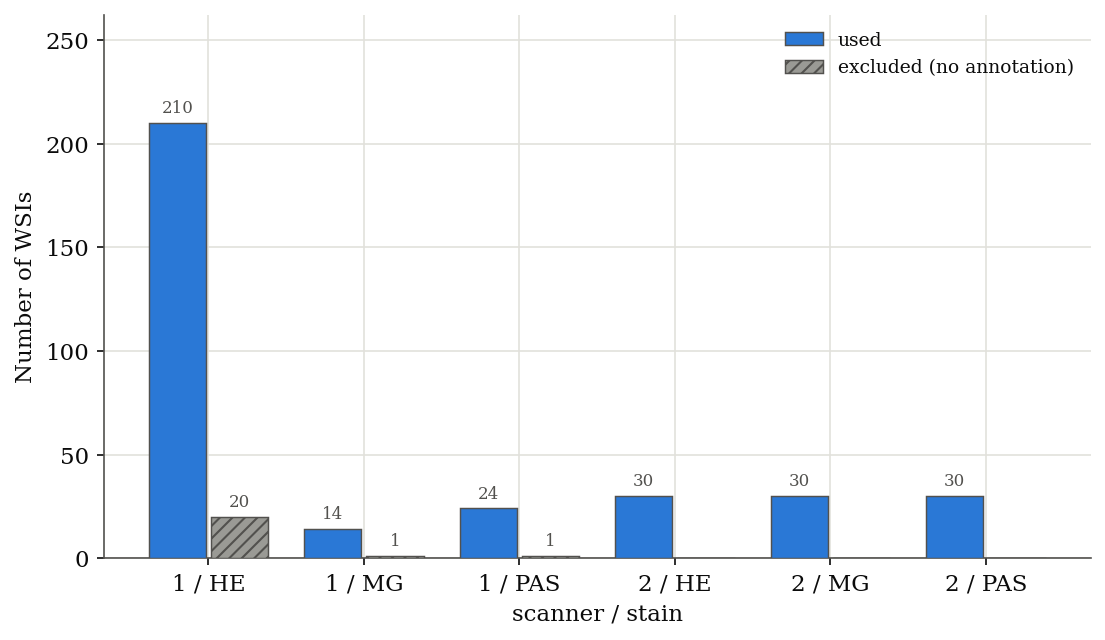

In [70]:
gsdb_raw_plot_ct = pd.crosstab(
    gsdb_raw["scanner_id"].astype(str) + " / " + gsdb_raw["stain"], gsdb_raw["split_status"],
).rename_axis(index="scanner / stain")
grouped_crosstab_chart(
    gsdb_raw_plot_ct, "GSDB — raw corpus: used vs. excluded slides by scanner and stain",
    OVERVIEW_FIGURES_DIR / "gsdb_raw_scanner_x_stain_x_split_status.png",
    colors={"used": ACCENT, "excluded (no annotation)": NEUTRAL},
    class_order=["used", "excluded (no annotation)"], ylabel="Number of WSIs", xlabel="scanner / stain",
)

In [71]:
gsdb_raw_excluded = save_table(
    gsdb_raw.loc[~gsdb_raw["annotated"], ["slide_name", "slide_id", "patient_id", "scanner_id", "stain", "has_annotation_file"]],
    "gsdb_raw_excluded_slides",
)
gsdb_raw_excluded

,slide_name,slide_id,patient_id,scanner_id,stain,has_annotation_file
5,6_4_1_HE,6,4,1,HE,True
12,13_9_1_HE,13,9,1,HE,True
19,20_14_1_HE,20,14,1,HE,True
25,26_18_1_HE,26,18,1,HE,True
33,34_24_1_HE,34,24,1,HE,True
40,41_29_1_HE,41,29,1,HE,True
47,48_34_1_HE,48,34,1,HE,True
54,55_39_1_HE,55,39,1,HE,True
61,62_44_1_HE,62,44,1,HE,True
68,69_49_1_HE,69,49,1,HE,True


In [72]:

gsdb_overview_facts = pd.DataFrame([{
    "n_slides_raw": len(gsdb_raw),
    "n_slides_raw_annotated": int(gsdb_raw["annotated"].sum()),
    "n_patients_raw": gsdb_raw["patient_id"].nunique(),
    "n_slides_main_split": len(gsdb_all),
    "n_slides_incl_scanner2": len(gsdb_full),
    "n_patients_main_split": gsdb_all["patient_id"].nunique(),
    "n_patients_incl_scanner2": gsdb_full["patient_id"].nunique(),
    "n_scanners": gsdb_full["scanner_id"].nunique(),
    "n_stains": gsdb_full["stain"].nunique(),
    "n_graphs_inflammation_dir": len(list(GSDB_INFLAMMATION_GRAPH_DIR.glob("*.pt"))),
    "n_graphs_tissue_dir": len(list(GSDB_TISSUE_GRAPH_DIR.glob("*.pt"))),
    "total_corpus_size_gb_inflammation": round(sum(r.get("file_size_bytes") or 0 for r in gsdb_infl_records) / 1e9, 1),
    "total_corpus_size_gb_tissue": round(sum(r.get("file_size_bytes") or 0 for r in gsdb_tissue_records) / 1e9, 1),
}])
save_table(gsdb_overview_facts, "gsdb_overview_facts")
gsdb_overview_facts


,n_slides_raw,n_slides_raw_annotated,n_patients_raw,n_slides_main_split,n_slides_incl_scanner2,n_patients_main_split,n_patients_incl_scanner2,n_scanners,n_stains,n_graphs_inflammation_dir,n_graphs_tissue_dir,total_corpus_size_gb_inflammation,total_corpus_size_gb_tissue
0,360,338,274,248,338,222,252,2,3,333,333,36.7,36.7


In [73]:

gsdb_slide_counts = gsdb_all["inflammation_status"].value_counts().to_dict()
gsdb_region_counts = counts_dict(dataset_patch_region_level_table(gsdb_all, gsdb_infl_hier, "region", ["inflamed", "noninflamed", "other", "unknown", "mixed"]))
gsdb_patch_counts = counts_dict(dataset_patch_region_level_table(gsdb_all, gsdb_infl_hier, "patch", ["inflamed", "noninflamed", "other", "unknown", "mixed"]))


In [74]:

gsdb_infl_colors = {"inflamed": ACCENT, "noninflamed": NEUTRAL, "other": LIGHT_GRAY,
                     "unknown": UNKNOWN_GRAY, "mixed": MIXED_GRAY}
gsdb_infl_class_order = ["inflamed", "noninflamed", "other", "unknown", "mixed"]

gsdb_infl_by_granularity = {
    "Slide": gsdb_slide_counts,
    "Region": gsdb_region_counts,
    "Patch": gsdb_patch_counts,
}
gsdb_infl_detail = save_table(
    detailed_table(gsdb_infl_by_granularity, gsdb_infl_class_order),
    "gsdb_inflammation_status_detailed_by_granularity",
)
gsdb_infl_detail


,granularity,class,n,pct_of_granularity,n_total_at_granularity
0,Slide,inflamed,138,55.65,248
1,Slide,noninflamed,100,40.32,248
2,Slide,other,10,4.03,248
3,Region,inflamed,11755,37.69,31187
4,Region,noninflamed,4971,15.94,31187
5,Region,other,879,2.82,31187
6,Region,unknown,4216,13.52,31187
7,Region,mixed,9366,30.03,31187
8,Patch,inflamed,1133682,52.74,2149490
9,Patch,noninflamed,580860,27.02,2149490


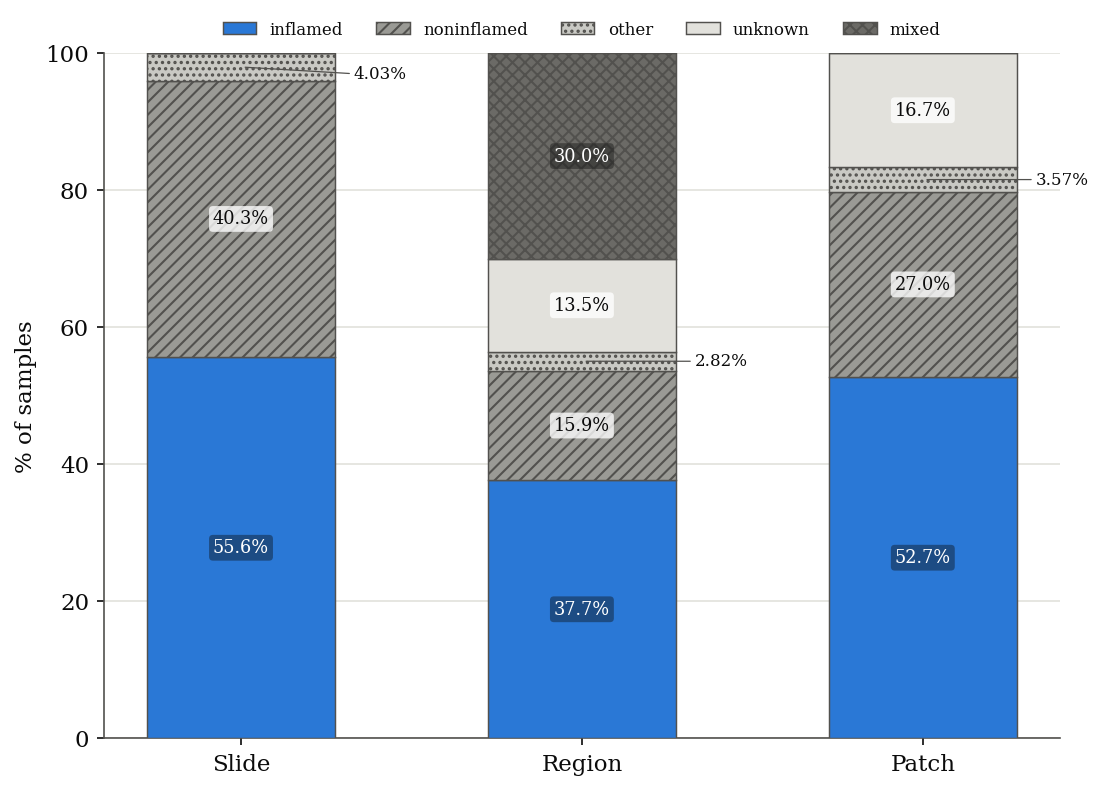

In [75]:

detailed_stacked_chart(
    gsdb_infl_by_granularity, "GSDB — inflammation_status breakdown by granularity",
    IMBALANCE_FIGURES_DIR / "gsdb_inflammation_status_detailed_by_granularity.png",
    gsdb_infl_class_order, gsdb_infl_colors,
)


In [76]:

gsdb_tissue_class_order = ["corpus", "antrum", "other", "unknown", "mixed", "intermediate"]
gsdb_tissue_colors = {"corpus": ACCENT, "antrum": NEUTRAL, "other": LIGHT_GRAY,
                       "unknown": UNKNOWN_GRAY, "mixed": MIXED_GRAY, "intermediate": EXTRA_GRAY}

gsdb_tissue_region_counts = counts_dict(dataset_patch_region_level_table(
    gsdb_all, gsdb_tissue_hier, "region", gsdb_tissue_class_order, field="tissue_type"))
gsdb_tissue_patch_counts = counts_dict(dataset_patch_region_level_table(
    gsdb_all, gsdb_tissue_hier, "patch", gsdb_tissue_class_order, field="tissue_type"))


In [77]:

gsdb_tissue_by_granularity = {
    "Region": gsdb_tissue_region_counts,
    "Patch": gsdb_tissue_patch_counts,
}
gsdb_tissue_detail = save_table(
    detailed_table(gsdb_tissue_by_granularity, gsdb_tissue_class_order),
    "gsdb_tissue_type_detailed_by_granularity",
)
gsdb_tissue_detail


,granularity,class,n,pct_of_granularity,n_total_at_granularity
0,Region,corpus,9403,30.15,31187
1,Region,antrum,7327,23.49,31187
2,Region,other,106,0.34,31187
3,Region,unknown,4216,13.52,31187
4,Region,mixed,9366,30.03,31187
5,Region,intermediate,769,2.47,31187
6,Patch,corpus,947539,44.08,2149490
7,Patch,antrum,734495,34.17,2149490
8,Patch,other,16442,0.76,2149490
9,Patch,unknown,358113,16.66,2149490


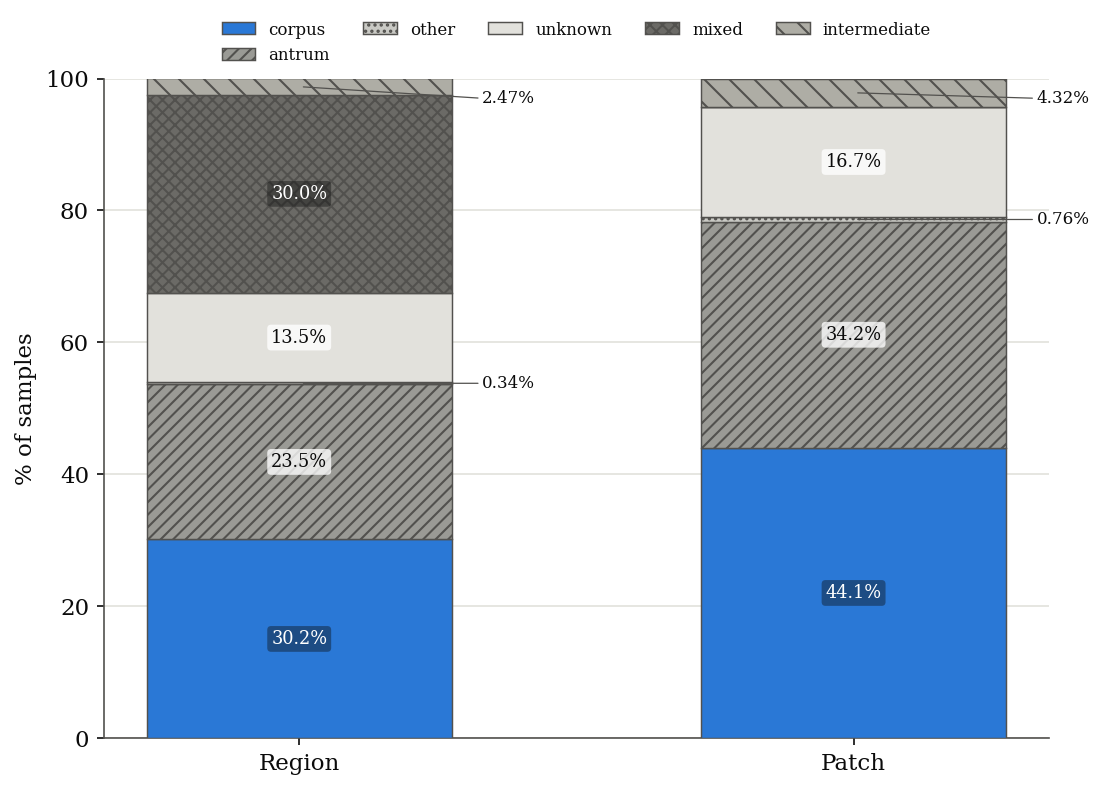

In [78]:

detailed_stacked_chart(
    gsdb_tissue_by_granularity, "GSDB — tissue_type breakdown by granularity",
    IMBALANCE_FIGURES_DIR / "gsdb_tissue_type_detailed_by_granularity.png",
    gsdb_tissue_class_order, gsdb_tissue_colors,
)


In [79]:

imbalance_summary = pd.DataFrame([
    imbalance_row("CAMELYON17", "Slide", camelyon_slide_counts, "tumor"),
    imbalance_row("CAMELYON17", "Region", camelyon_region_counts, "positive"),
    imbalance_row("CAMELYON17", "Patch", camelyon_patch_counts, "positive"),
    imbalance_row("GSDB", "Slide", gsdb_slide_counts, "inflamed"),
    imbalance_row("GSDB", "Region", gsdb_region_counts, "inflamed"),
    imbalance_row("GSDB", "Patch", gsdb_patch_counts, "inflamed"),
])
save_table(imbalance_summary, "class_imbalance_summary_slide_region_patch")
imbalance_summary


,dataset,granularity,positive_class,n_positive,n_negative_or_other,n_total,pct_positive,pct_negative_or_other,imbalance_ratio_negative_to_positive,imbalance_ratio_label
0,CAMELYON17,Slide,tumor,182,204,386,47.15,52.85,1.12,1.1:1
1,CAMELYON17,Region,positive,312,26386,26698,1.17,98.83,84.57,84.6:1
2,CAMELYON17,Patch,positive,69502,12204548,12274050,0.57,99.43,175.60,175.6:1
3,GSDB,Slide,inflamed,138,110,248,55.65,44.35,0.80,0.8:1
4,GSDB,Region,inflamed,11755,19432,31187,37.69,62.31,1.65,1.7:1
5,GSDB,Patch,inflamed,1133682,1015808,2149490,52.74,47.26,0.90,0.9:1


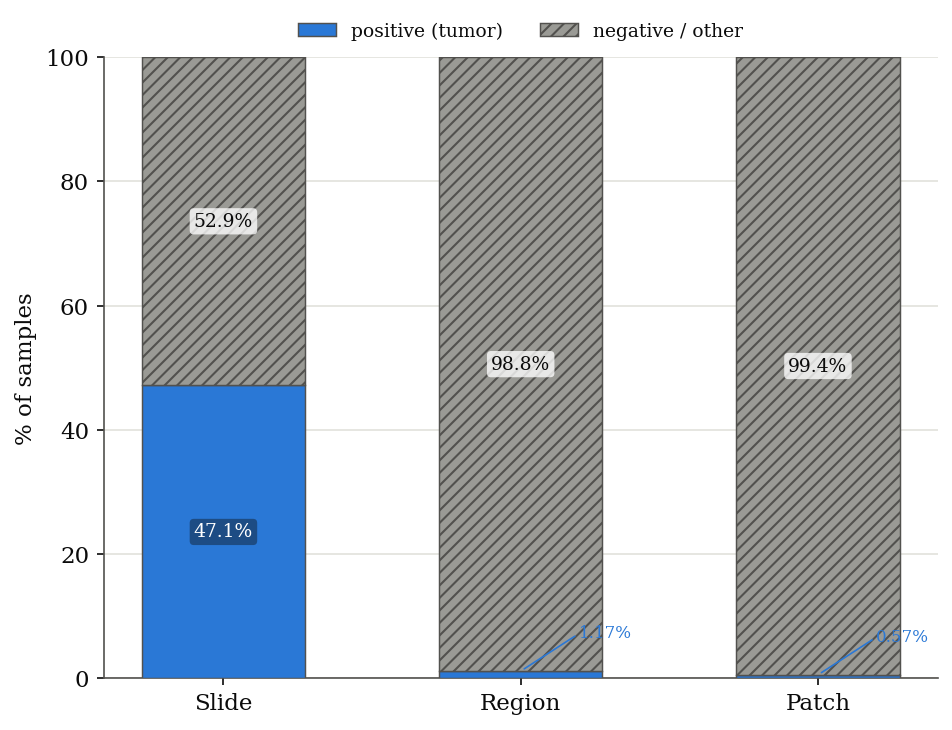

In [80]:

imbalance_bar_chart(imbalance_summary, "CAMELYON17", IMBALANCE_FIGURES_DIR / "camelyon_imbalance_by_granularity.png")


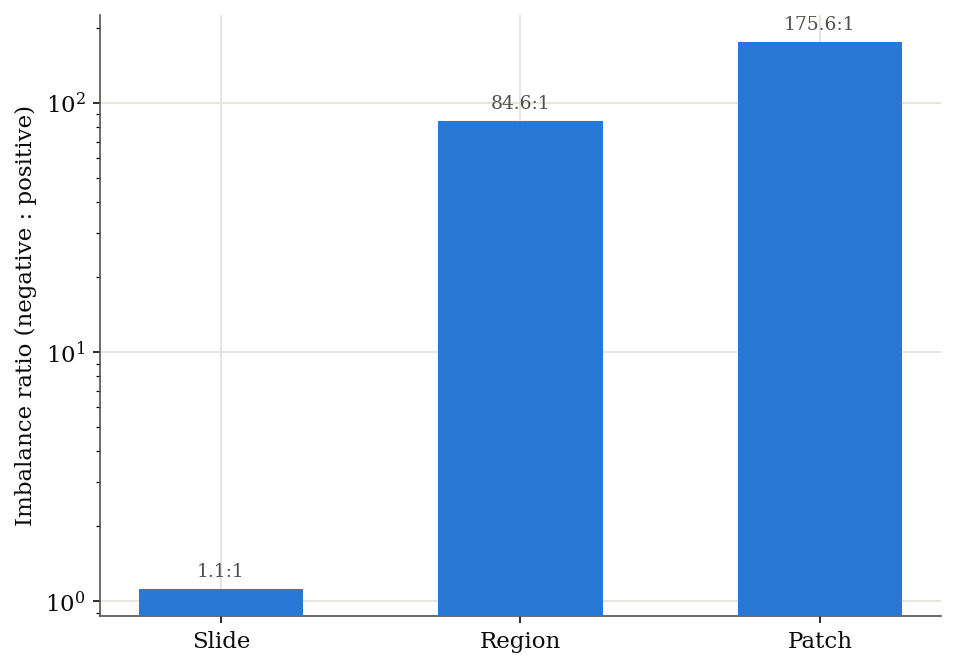

In [81]:

imbalance_ratio_chart(imbalance_summary, "CAMELYON17", IMBALANCE_FIGURES_DIR / "camelyon_imbalance_ratio_by_granularity.png")


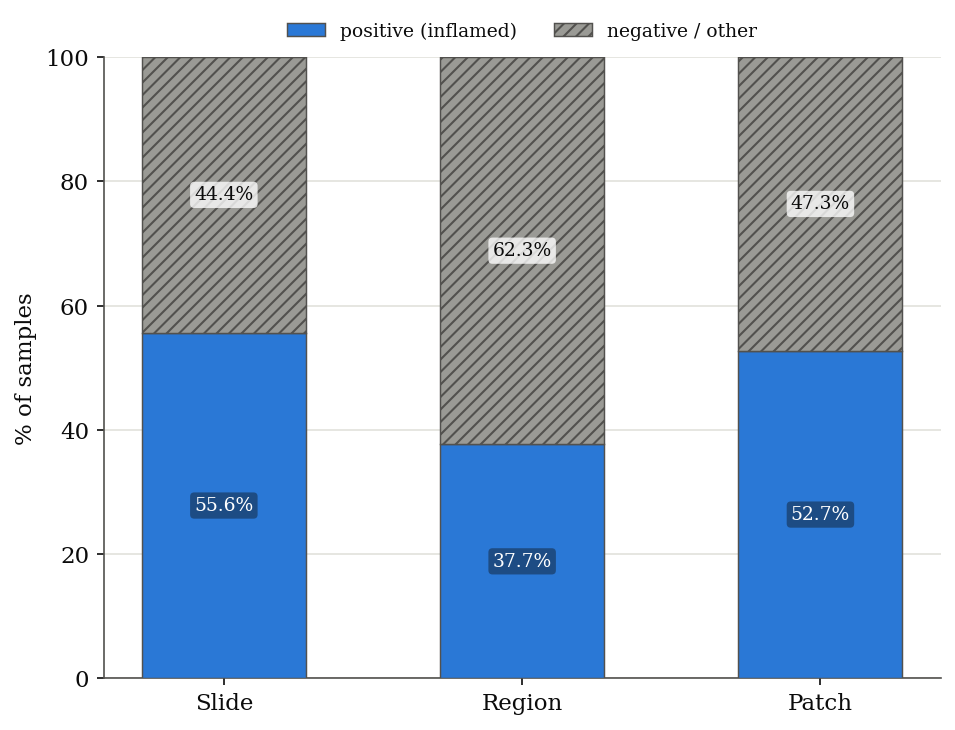

In [82]:

imbalance_bar_chart(imbalance_summary, "GSDB", IMBALANCE_FIGURES_DIR / "gsdb_imbalance_by_granularity.png")


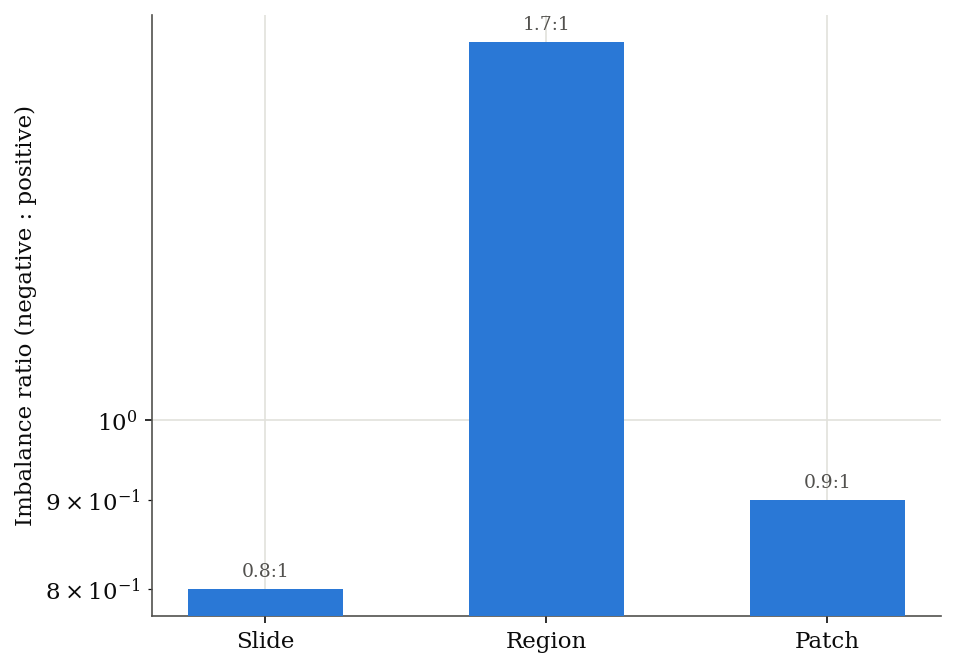

In [83]:

imbalance_ratio_chart(imbalance_summary, "GSDB", IMBALANCE_FIGURES_DIR / "gsdb_imbalance_ratio_by_granularity.png")


In [84]:

imbalance_summary = pd.concat([
    imbalance_summary,
    pd.DataFrame([
        imbalance_row("GSDB (tissue_type)", "Region", gsdb_tissue_region_counts, "corpus"),
        imbalance_row("GSDB (tissue_type)", "Patch", gsdb_tissue_patch_counts, "corpus"),
    ]),
], ignore_index=True)
save_table(imbalance_summary, "class_imbalance_summary_slide_region_patch")
imbalance_summary


,dataset,granularity,positive_class,n_positive,n_negative_or_other,n_total,pct_positive,pct_negative_or_other,imbalance_ratio_negative_to_positive,imbalance_ratio_label
0,CAMELYON17,Slide,tumor,182,204,386,47.15,52.85,1.12,1.1:1
1,CAMELYON17,Region,positive,312,26386,26698,1.17,98.83,84.57,84.6:1
2,CAMELYON17,Patch,positive,69502,12204548,12274050,0.57,99.43,175.60,175.6:1
3,GSDB,Slide,inflamed,138,110,248,55.65,44.35,0.80,0.8:1
4,GSDB,Region,inflamed,11755,19432,31187,37.69,62.31,1.65,1.7:1
5,GSDB,Patch,inflamed,1133682,1015808,2149490,52.74,47.26,0.90,0.9:1
6,GSDB (tissue_type),Region,corpus,9403,21784,31187,30.15,69.85,2.32,2.3:1
7,GSDB (tissue_type),Patch,corpus,947539,1201951,2149490,44.08,55.92,1.27,1.3:1


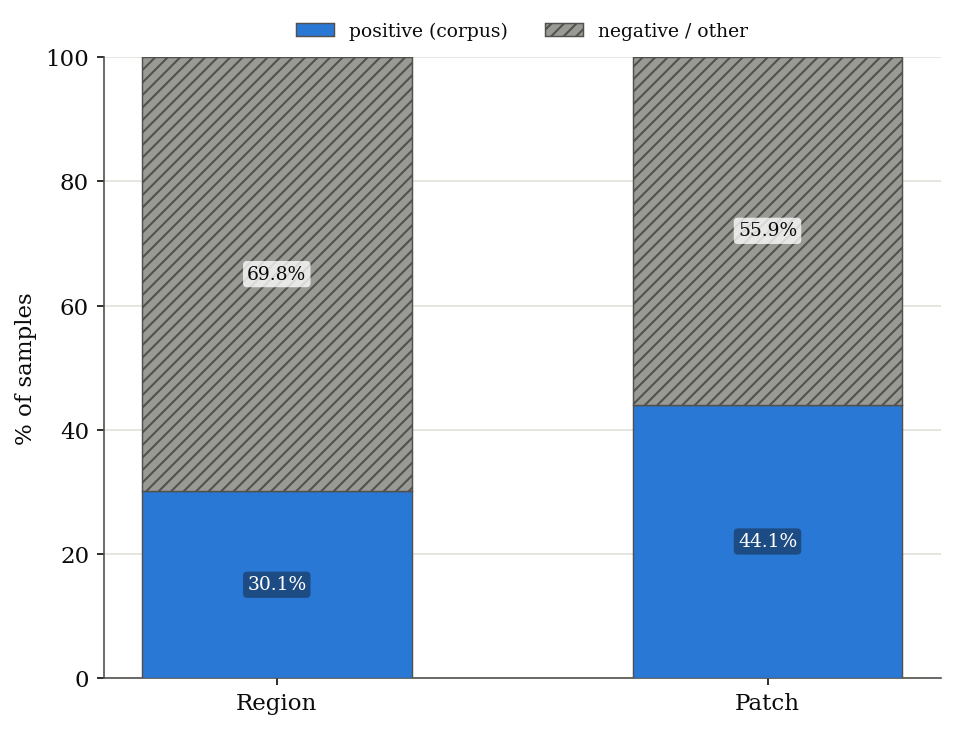

In [85]:

imbalance_bar_chart(imbalance_summary, "GSDB (tissue_type)", IMBALANCE_FIGURES_DIR / "gsdb_tissue_type_imbalance_by_granularity.png")


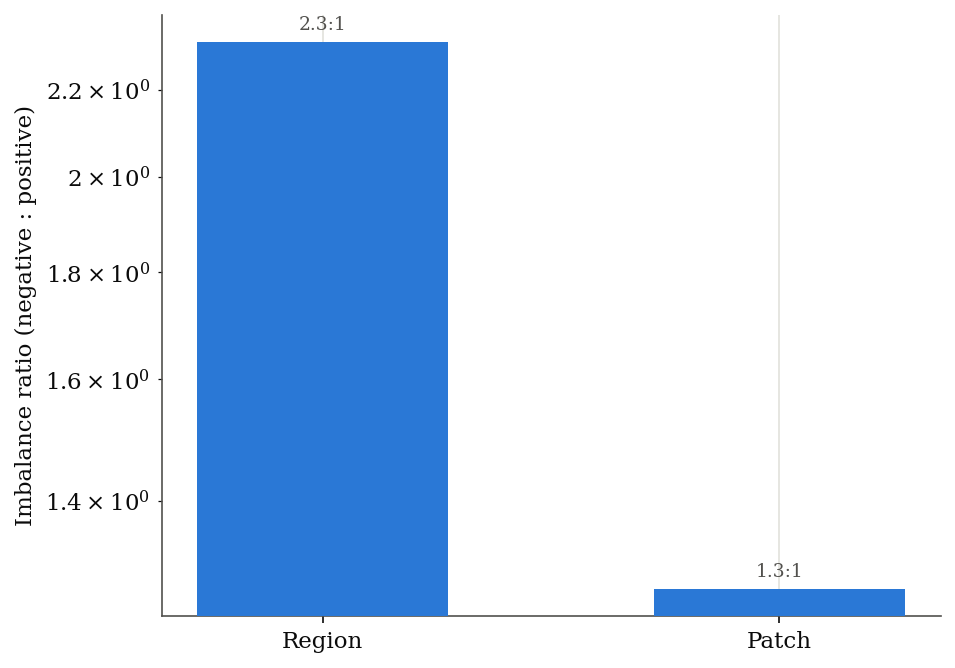

In [86]:

imbalance_ratio_chart(imbalance_summary, "GSDB (tissue_type)", IMBALANCE_FIGURES_DIR / "gsdb_tissue_type_imbalance_ratio_by_granularity.png")
